# Case Study 1: Building a Mean-Variance Portfolio Pipeline

DS 5005

**Return convention:** all returns in this notebook are **daily simple (percent) returns**, $r_t = P_t / P_{t-1} - 1$, used consistently throughout (Section 1 onward). Simple returns are used because they aggregate linearly *across assets within a period* a portfolio's return is just the weight-weighted sum of its holdings' simple returns, $r_{p,t} = \sum_i w_i r_{i,t}$. 

## Section 1 — Data Pipeline

Fetch daily adjusted closing prices for the eleven SPDR sector ETFs plus SPY (the market factor) using `yfinance`, with a local disk cache so repeated runs don't re-download data unnecessarily.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from pathlib import Path

RNG_SEED = 5005
np.random.seed(RNG_SEED)

TICKERS = ["XLC", "XLY", "XLP", "XLE", "XLF", "XLV", "XLI", "XLB",
           "XLRE", "XLK", "XLU", "SPY"]
MARKET_TICKER = "SPY"
SECTOR_TICKERS = [t for t in TICKERS if t != MARKET_TICKER]

# Relative path -> portable across machines / graders. Plain CSV so the cache
# doesn't require an optional parquet engine (pyarrow/fastparquet) to be installed.
CACHE_PATH = Path("cs1_price_cache.csv")
START_DATE = "2010-01-01"

In [2]:
def _most_recent_trading_day(as_of=None):
    """Naive expected most-recent trading day: today, rolled back over weekends.
    Doesn't account for exchange holidays, so it can be off by a day around them;
    that just costs one harmless extra network check, never a stale silent cache."""
    as_of = pd.Timestamp(as_of) if as_of is not None else pd.Timestamp.now()
    as_of = as_of.normalize()
    while as_of.weekday() >= 5:  # 5=Sat, 6=Sun
        as_of -= pd.Timedelta(days=1)
    return as_of


def _download_prices(tickers, start, end=None):
    """Download adjusted close prices for `tickers` from `start` to `end`."""
    raw = yf.download(tickers, start=start, end=end, auto_adjust=True,
                       progress=False)["Close"]
    if isinstance(raw, pd.Series):  # single-ticker download collapses to a Series
        raw = raw.to_frame(tickers[0] if len(tickers) == 1 else tickers)
    raw.columns.name = None
    return raw.sort_index()


def get_price_cache(tickers=TICKERS, cache_path=CACHE_PATH, start=START_DATE):
    """Return a DataFrame of adjusted close prices, using and updating a local
    on-disk cache. See the prose cell below for the invalidation rule."""
    expected_last = _most_recent_trading_day()

    if cache_path.exists():
        cached = pd.read_csv(cache_path, index_col=0)
        cached.index = pd.to_datetime(cached.index)
        have_all = set(tickers).issubset(cached.columns)
        is_fresh = have_all and cached.index.max().normalize() >= expected_last
        if is_fresh:
            return cached[tickers]

        if have_all:
            fetch_start = (cached.index.max() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
            fresh = _download_prices(tickers, start=fetch_start)
            combined = pd.concat([cached[tickers], fresh])
            combined = combined[~combined.index.duplicated(keep="last")].sort_index()
        else:
            # ticker list changed since the cache was written -> full re-download
            combined = _download_prices(tickers, start=start)
    else:
        combined = _download_prices(tickers, start=start)

    combined.to_csv(cache_path)
    return combined


def get_returns(tickers=TICKERS, cache_path=CACHE_PATH, start=START_DATE):
    """Return a clean DataFrame of daily simple (percent) returns: dates as
    index, tickers as columns, NaN rows dropped."""
    prices = get_price_cache(tickers, cache_path, start)
    returns = prices.pct_change()
    return returns.dropna(how="any")

**Cache design and invalidation logic.** `get_price_cache` stores adjusted close prices in a plain CSV file at a relative path (`cs1_price_cache.csv`), so it works on any machine. On each call, compute the *expected* most recent trading day without touching the network. If the cache exists, covers all requested tickers, and its last date already reaches that expected day, read straight from disk with no network call. Otherwise only download the *missing* tail, append it to the cached data, deduplicate, and re-save. If the requested ticker list doesn't match what's cached, fall back to a full re-download.

In [3]:
prices = get_price_cache()
first_valid = prices.apply(lambda s: s.first_valid_index())
first_valid.sort_values()

XLY    2010-01-04
XLP    2010-01-04
XLE    2010-01-04
XLF    2010-01-04
XLV    2010-01-04
XLI    2010-01-04
XLB    2010-01-04
XLK    2010-01-04
XLU    2010-01-04
SPY    2010-01-04
XLRE   2015-10-08
XLC    2018-06-19
dtype: datetime64[us]

A couple of sector ETFs (notably **XLC**, launched June 2018, and **XLRE**, launched October 2015) are younger than the others, so requiring all 12 tickers to be non-missing (`dropna(how="any")`) truncates the usable common history to start at XLC's inception rather than our requested `START_DATE`. 

In [4]:
returns = get_returns()
print(returns.shape)
print(f"Date range: {returns.index.min().date()} to {returns.index.max().date()}")
returns.head()

(2064, 12)
Date range: 2018-06-20 to 2026-09-04


,XLC,XLY,XLP,XLE,XLF,XLV,XLI,XLB,XLRE,XLK,XLU,SPY
Date,,,,,,,,,,,,
2018-06-20,0.012410,0.004742,0.000980,0.004415,-0.002559,0.002121,0.000683,-0.003249,0.010794,0.002100,0.000797,0.001706
2018-06-21,-0.006129,-0.007123,0.001957,-0.018516,-0.002933,-0.005762,-0.012554,-0.010635,0.005967,-0.007684,0.003385,-0.006269
2018-06-22,0.004377,-0.001704,0.008201,0.019951,-0.004779,0.004494,0.003455,0.014564,0.008742,-0.003238,0.006944,0.001823
2018-06-25,-0.020598,-0.021739,0.005036,-0.020093,-0.010713,-0.009184,-0.012670,-0.015551,-0.002476,-0.020763,0.016552,-0.013613
2018-06-26,0.001658,0.007163,-0.004240,0.012629,-0.003361,-0.003090,0.003766,0.003819,0.005275,0.004038,0.001163,0.002214


In [5]:
returns.describe().T

,count,mean,std,min,25%,50%,75%,max
XLC,2064.0,0.000527,0.013937,-0.112795,-0.005742,0.001096,0.007640,0.089901
XLY,2064.0,0.000500,0.015050,-0.126686,-0.006725,0.001275,0.008534,0.108881
XLP,2064.0,0.000397,0.009849,-0.093956,-0.004292,0.000561,0.005399,0.085107
XLE,2064.0,0.000631,0.019961,-0.201412,-0.009065,0.001146,0.010344,0.160373
XLF,2064.0,0.000546,0.014614,-0.137093,-0.005861,0.000975,0.007499,0.131566
XLV,2064.0,0.000468,0.011003,-0.098610,-0.005011,0.000539,0.006024,0.077057
XLI,2064.0,0.000578,0.013426,-0.113441,-0.005575,0.000923,0.007351,0.126512
XLB,2064.0,0.000457,0.013817,-0.110084,-0.006916,0.000683,0.007864,0.117601
XLRE,2064.0,0.000387,0.013705,-0.160011,-0.006150,0.000895,0.007297,0.087800
XLK,2064.0,0.000982,0.016870,-0.138140,-0.007359,0.001713,0.009991,0.134257


## Section 2 — Parameter and Model Uncertainty

### 2.1 — Simulation Study (No Model Risk)

In [6]:
rng21 = np.random.default_rng(RNG_SEED)

mu_star_full = returns[TICKERS].mean().to_numpy()
Sigma_star_full = returns[TICKERS].cov().to_numpy()
K_FULL = len(TICKERS)

N_GRID = [63, 126, 252, 504, 1008, 2520]
N_SIMS_21 = 500


def simulate_moments(mu_star, Sigma_star, n, n_sims, rng):
    """Draw n_sims independent samples of size n from N(mu_star, Sigma_star)
    and return the sample mean and sample covariance of each."""
    k = mu_star.shape[0]
    samples = rng.multivariate_normal(mu_star, Sigma_star, size=(n_sims, n))
    mu_hats = samples.mean(axis=1)
    centered = samples - mu_hats[:, None, :]
    Sigma_hats = np.einsum("sik,sil->skl", centered, centered) / (n - 1)
    return mu_hats, Sigma_hats


w_fixed_21 = np.ones(K_FULL) / K_FULL
true_port_mu_21 = w_fixed_21 @ mu_star_full
true_port_var_21 = w_fixed_21 @ Sigma_star_full @ w_fixed_21
true_sharpe_21 = (true_port_mu_21 * 252) / (np.sqrt(true_port_var_21) * np.sqrt(252))

results_21 = {}
for n in N_GRID:
    mu_hats, Sigma_hats = simulate_moments(mu_star_full, Sigma_star_full, n, N_SIMS_21, rng21)
    rmse_mu = np.sqrt(np.mean((mu_hats - mu_star_full) ** 2))
    frob = np.linalg.norm(Sigma_hats - Sigma_star_full, ord="fro", axis=(1, 2))
    port_mu = mu_hats @ w_fixed_21
    port_var = np.einsum("i,sij,j->s", w_fixed_21, Sigma_hats, w_fixed_21)
    port_sharpe = (port_mu * 252) / (np.sqrt(port_var) * np.sqrt(252))
    results_21[n] = dict(
        mu_hats=mu_hats, frob=frob, rmse_mu=rmse_mu,
        frob_mean=frob.mean(), sharpe=port_sharpe,
    )

summary_21 = pd.DataFrame({
    "n": N_GRID,
    "RMSE(mu)": [results_21[n]["rmse_mu"] for n in N_GRID],
    "Mean Frobenius norm (Sigma_hat - Sigma*)": [results_21[n]["frob_mean"] for n in N_GRID],
    "Std of estimated Sharpe (fixed w)": [results_21[n]["sharpe"].std() for n in N_GRID],
})
summary_21

,n,RMSE(mu),Mean Frobenius norm (Sigma_hat - Sigma*),Std of estimated Sharpe (fixed w)
0,63,0.001746,0.000352,1.990112
1,126,0.001231,0.000238,1.361143
2,252,0.000903,0.000169,1.019053
3,504,0.000620,0.000117,0.696655
4,1008,0.000424,0.000086,0.462201
5,2520,0.000275,0.000055,0.303752


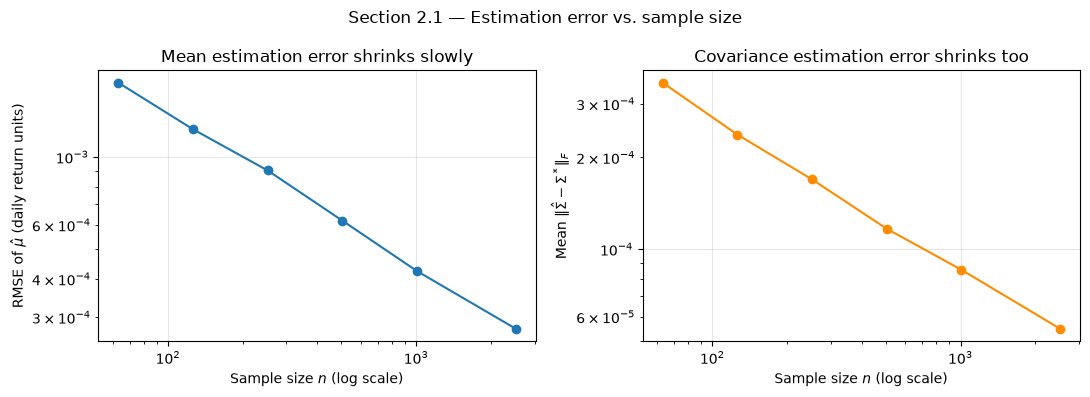

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(summary_21["n"], summary_21["RMSE(mu)"], marker="o")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Sample size $n$ (log scale)")
axes[0].set_ylabel(r"RMSE of $\hat{\mu}$ (daily return units)")
axes[0].set_title("Mean estimation error shrinks slowly")
axes[0].grid(alpha=0.3)

axes[1].plot(summary_21["n"], summary_21["Mean Frobenius norm (Sigma_hat - Sigma*)"],
             marker="o", color="darkorange")
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Sample size $n$ (log scale)")
axes[1].set_ylabel(r"Mean $\|\hat{\Sigma} - \Sigma^*\|_F$")
axes[1].set_title("Covariance estimation error shrinks too")
axes[1].grid(alpha=0.3)

fig.suptitle("Section 2.1 — Estimation error vs. sample size")
fig.tight_layout()
plt.show()

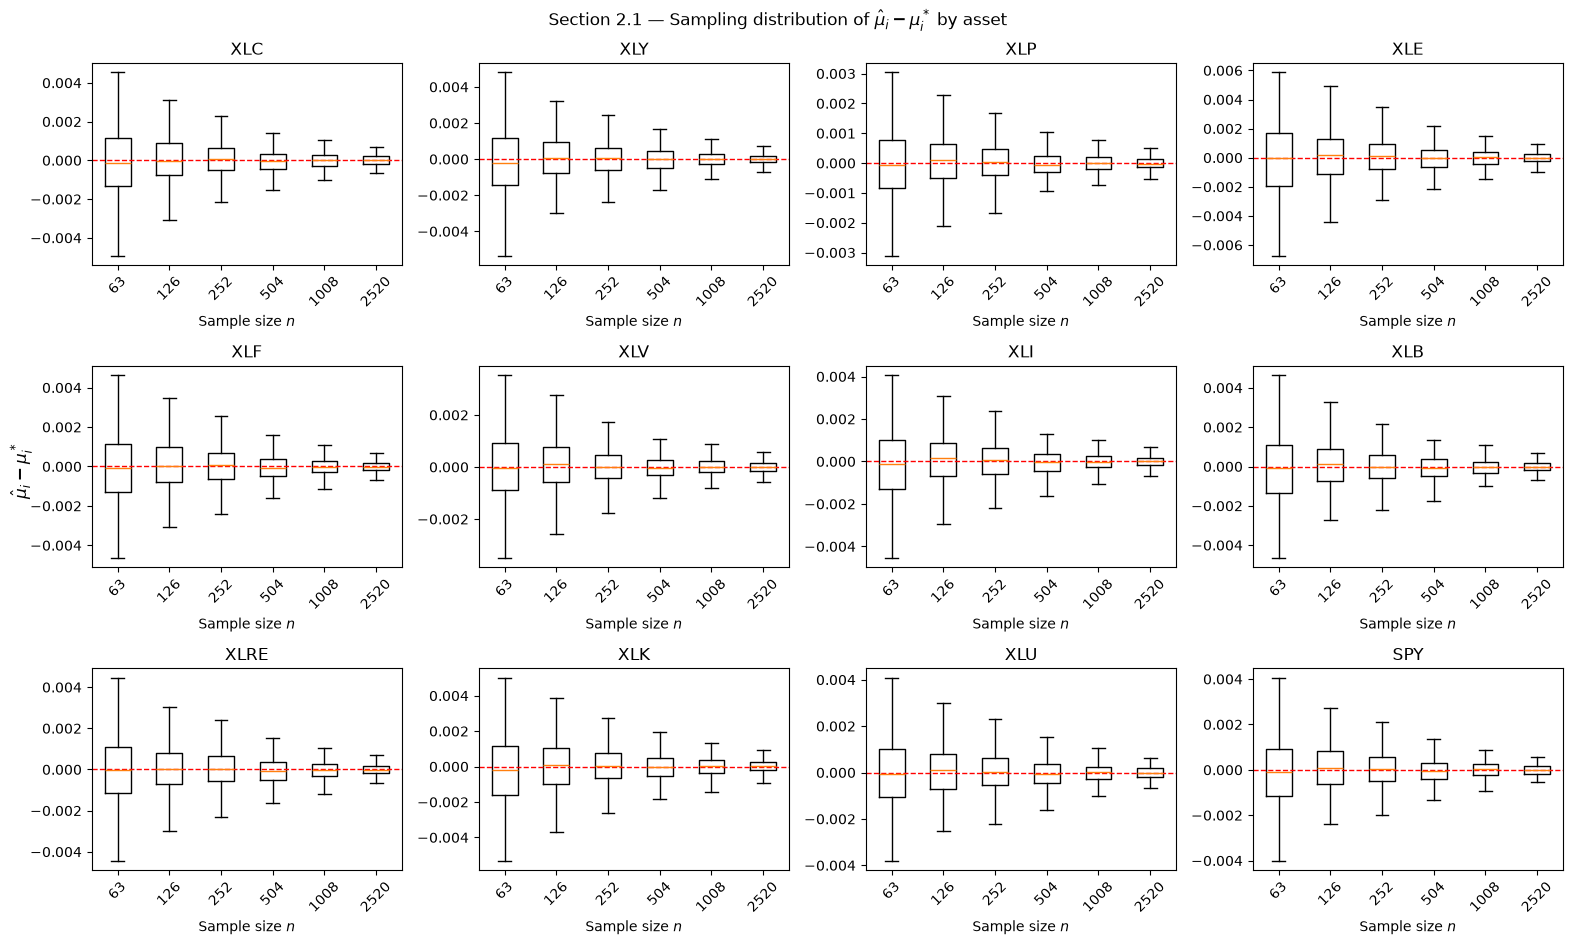

In [8]:
assets_to_show = TICKERS  # all 11 sector ETFs + SPY
ncols = 4
nrows = int(np.ceil(len(assets_to_show) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.2 * nrows), sharey=False)
axes_flat = axes.flatten()
for ax, asset in zip(axes_flat, assets_to_show):
    j = TICKERS.index(asset)
    data = [results_21[n]["mu_hats"][:, j] - mu_star_full[j] for n in N_GRID]
    ax.boxplot(data, tick_labels=[str(n) for n in N_GRID], showfliers=False)
    ax.axhline(0, color="red", linestyle="--", linewidth=1)
    ax.set_title(f"{asset}")
    ax.set_xlabel("Sample size $n$")
    ax.tick_params(axis="x", rotation=45)
for ax in axes_flat[len(assets_to_show):]:
    ax.set_visible(False)
fig.supylabel(r"$\hat{\mu}_i - \mu_i^*$")
fig.suptitle(r"Section 2.1 — Sampling distribution of $\hat{\mu}_i - \mu_i^*$ by asset")
fig.tight_layout()
plt.show()

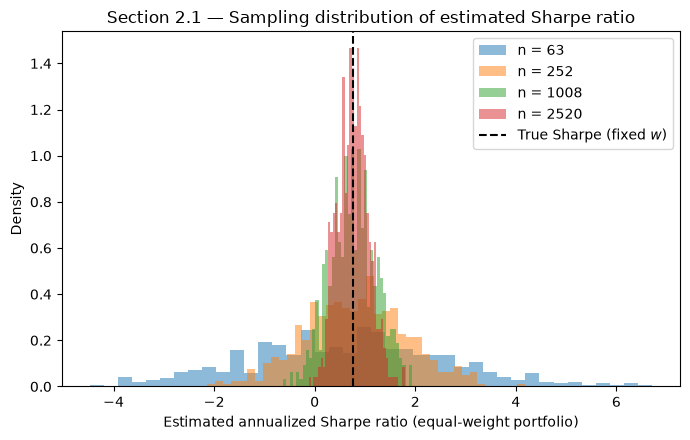

True (fixed-w) annualized Sharpe ratio: 0.764


In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
n_to_plot = [63, 252, 1008, 2520]
for n in n_to_plot:
    ax.hist(results_21[n]["sharpe"], bins=40, alpha=0.5, density=True,
            label=f"n = {n}")
ax.axvline(true_sharpe_21, color="black", linestyle="--", label="True Sharpe (fixed $w$)")
ax.set_xlabel("Estimated annualized Sharpe ratio (equal-weight portfolio)")
ax.set_ylabel("Density")
ax.set_title("Section 2.1 — Sampling distribution of estimated Sharpe ratio")
ax.legend()
fig.tight_layout()
plt.show()

print(f"True (fixed-w) annualized Sharpe ratio: {true_sharpe_21:.3f}")

**Interpretation (2.1).** Both $\hat{\boldsymbol{\mu}}$ and $\hat{\boldsymbol{\Sigma}}$ improve as $n$ grows. However, they are not equally reliable. Mean returns are tiny relative to daily volatility, so even at $n=2520$ (ten years) the boxplots show $\hat{\mu}_i - \mu_i^*$ still has a spread comparable to the true mean itself. In contrast, the covariance matrix, is estimated from $n \times k$ effective data points per fit rather than $n$, so its precision improves much faster; by $n \approx 252$–$504$ the Frobenius norm has dropped substantially and the Sharpe-ratio sampling distribution, while still wide at $n=63$, is already fairly concentrated by $n=1008$–$2520$. With only a few hundred days of data, trust $\hat{\boldsymbol{\Sigma}}$ far more than $\hat{\boldsymbol{\mu}}$. 'Good enough' is relative to the question. It could be the case that one question is satisfactory with only 63, where another would require more datapoints. 

### 2.2 — Model Uncertainty on Real Data

In [10]:
import statsmodels.api as sm

sample_mu = returns[SECTOR_TICKERS].mean()
sample_Sigma = returns[SECTOR_TICKERS].cov()

alphas, betas, resid_vars = {}, {}, {}
market = returns[MARKET_TICKER]
X = sm.add_constant(market)
for ticker in SECTOR_TICKERS:
    fit = sm.OLS(returns[ticker], X).fit()
    alphas[ticker] = fit.params["const"]
    betas[ticker] = fit.params[MARKET_TICKER]
    resid_vars[ticker] = fit.mse_resid

alphas = pd.Series(alphas)
betas = pd.Series(betas)
resid_vars = pd.Series(resid_vars)

market_mean = market.mean()
market_var = market.var(ddof=1)

capm_mu = alphas + betas * market_mean
capm_Sigma = pd.DataFrame(
    np.outer(betas, betas) * market_var + np.diag(resid_vars),
    index=SECTOR_TICKERS, columns=SECTOR_TICKERS,
)

print("CAPM betas:")
print(betas.round(3))

CAPM betas:
XLC     0.986
XLY     1.112
XLP     0.526
XLE     0.944
XLF     1.006
XLV     0.687
XLI     0.973
XLB     0.944
XLRE    0.808
XLK     1.288
XLU     0.606
dtype: float64


In [11]:
print("Sample mean vector (annualized, %):")
display((sample_mu * 252 * 100).round(2))
print("\nCAPM mean vector (annualized, %):")
display((capm_mu * 252 * 100).round(2))

sample_corr = sample_Sigma / np.outer(np.sqrt(np.diag(sample_Sigma)), np.sqrt(np.diag(sample_Sigma)))
capm_corr = capm_Sigma / np.outer(np.sqrt(np.diag(capm_Sigma)), np.sqrt(np.diag(capm_Sigma)))
print("\nSample correlation matrix:")
display(sample_corr.round(2))
print("\nCAPM-implied correlation matrix:")
display(capm_corr.round(2))

Sample mean vector (annualized, %):


XLC     13.27
XLY     12.59
XLP     10.01
XLE     15.90
XLF     13.75
XLV     11.78
XLI     14.56
XLB     11.51
XLRE     9.75
XLK     24.74
XLU     11.71
dtype: float64


CAPM mean vector (annualized, %):


XLC     13.27
XLY     12.59
XLP     10.01
XLE     15.90
XLF     13.75
XLV     11.78
XLI     14.56
XLB     11.51
XLRE     9.75
XLK     24.74
XLU     11.71
dtype: float64


Sample correlation matrix:


,XLC,XLY,XLP,XLE,XLF,XLV,XLI,XLB,XLRE,XLK,XLU
XLC,1.00,0.81,0.53,0.41,0.67,0.61,0.67,0.65,0.58,0.78,0.41
XLY,0.81,1.00,0.53,0.44,0.72,0.61,0.76,0.72,0.62,0.81,0.43
XLP,0.53,0.53,1.00,0.39,0.61,0.71,0.61,0.63,0.69,0.45,0.70
XLE,0.41,0.44,0.39,1.00,0.67,0.44,0.64,0.63,0.44,0.40,0.37
XLF,0.67,0.72,0.61,0.67,1.00,0.66,0.86,0.81,0.67,0.64,0.54
XLV,0.61,0.61,0.71,0.44,0.66,1.00,0.68,0.68,0.68,0.59,0.60
XLI,0.67,0.76,0.61,0.64,0.86,0.68,1.00,0.87,0.69,0.72,0.58
XLB,0.65,0.72,0.63,0.63,0.81,0.68,0.87,1.00,0.69,0.66,0.56
XLRE,0.58,0.62,0.69,0.44,0.67,0.68,0.69,0.69,1.00,0.54,0.75
XLK,0.78,0.81,0.45,0.40,0.64,0.59,0.72,0.66,0.54,1.00,0.40



CAPM-implied correlation matrix:


,XLC,XLY,XLP,XLE,XLF,XLV,XLI,XLB,XLRE,XLK,XLU
XLC,1.00,0.76,0.55,0.49,0.71,0.64,0.75,0.71,0.61,0.79,0.49
XLY,0.76,1.00,0.58,0.51,0.74,0.67,0.78,0.74,0.64,0.82,0.51
XLP,0.55,0.58,1.00,0.37,0.54,0.49,0.56,0.53,0.46,0.59,0.37
XLE,0.49,0.51,0.37,1.00,0.48,0.43,0.50,0.47,0.41,0.53,0.33
XLF,0.71,0.74,0.54,0.48,1.00,0.63,0.73,0.69,0.59,0.77,0.47
XLV,0.64,0.67,0.49,0.43,0.63,1.00,0.66,0.62,0.54,0.70,0.43
XLI,0.75,0.78,0.56,0.50,0.73,0.66,1.00,0.72,0.62,0.81,0.50
XLB,0.71,0.74,0.53,0.47,0.69,0.62,0.72,1.00,0.59,0.76,0.47
XLRE,0.61,0.64,0.46,0.41,0.59,0.54,0.62,0.59,1.00,0.66,0.41
XLK,0.79,0.82,0.59,0.53,0.77,0.70,0.81,0.76,0.66,1.00,0.53


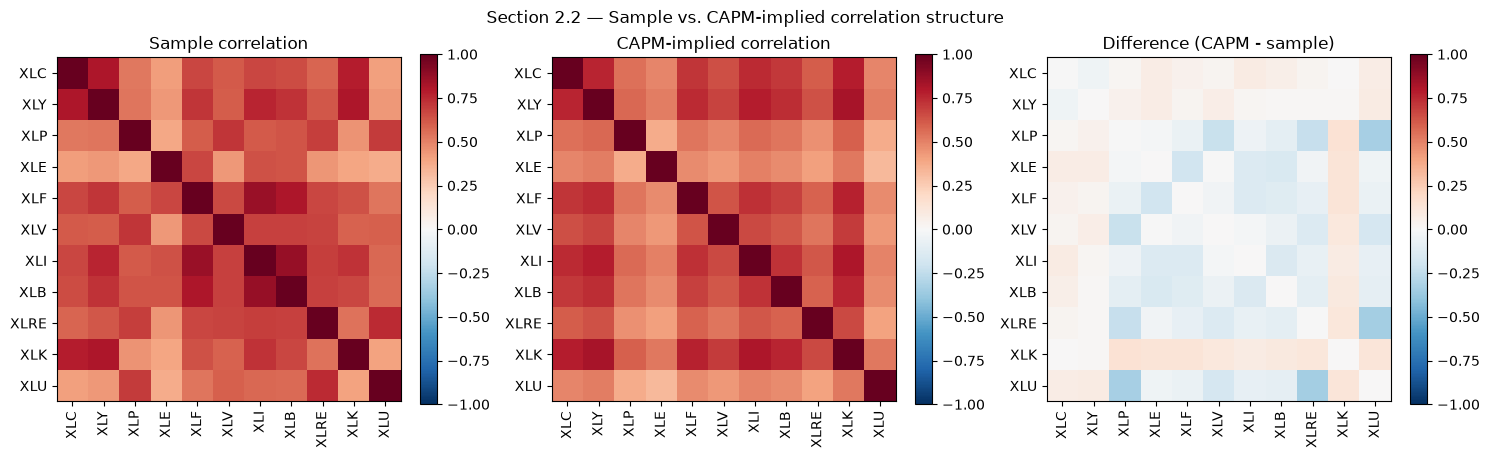

Largest |CAPM mu - sample mu| (annualized, %):
XLB    0.0
XLI    0.0
XLK    0.0
dtype: float64

Largest off-diagonal |CAPM Sigma - sample Sigma| entry: (XLRE, XLU) = 0.000060


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, mat, title in zip(
    axes, [sample_corr, capm_corr, capm_corr - sample_corr],
    ["Sample correlation", "CAPM-implied correlation", "Difference (CAPM - sample)"],
):
    im = ax.imshow(mat, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(SECTOR_TICKERS)))
    ax.set_xticklabels(SECTOR_TICKERS, rotation=90)
    ax.set_yticks(range(len(SECTOR_TICKERS)))
    ax.set_yticklabels(SECTOR_TICKERS)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.suptitle("Section 2.2 — Sample vs. CAPM-implied correlation structure")
fig.tight_layout()
plt.show()

diff = (capm_mu - sample_mu).abs().sort_values(ascending=False)
print("Largest |CAPM mu - sample mu| (annualized, %):")
print((diff * 252 * 100).round(6).head(3))

Sigma_diff_vals = (capm_Sigma - sample_Sigma).abs().to_numpy().copy()
np.fill_diagonal(Sigma_diff_vals, -np.inf)
i, j = np.unravel_index(np.argmax(Sigma_diff_vals), Sigma_diff_vals.shape)
print(f"\nLargest off-diagonal |CAPM Sigma - sample Sigma| entry: "
      f"({SECTOR_TICKERS[i]}, {SECTOR_TICKERS[j]}) = {Sigma_diff_vals[i, j]:.6f}")

**Comparison (2.2).** The mean vectors are extremly close between the two methods. OLS with an intercept guarantees the fitted regression line passes through the point of means, i.e. $\hat\alpha_i = \bar r_i - \hat\beta_i \bar r_m$ exactly, so $\hat\mu_{\text{CAPM},i} = \hat\alpha_i + \hat\beta_i \bar r_m$ algebraically collapses back to the plain sample mean $\bar r_i$ for every asset. CAPM's added value is in the covariance matrix. There, the two methods disagree. The CAPM correlation matrix is smoother than the sample correlation matrix. One-factor structure forces all off-diagonal covariance to flow through a common market beta ($\hat\Sigma_{ij} = \hat\beta_i\hat\beta_j\hat\sigma_m^2$ for $i \neq j$) and so cannot represent sector-pair co-movement that isn't explained by shared market exposure. The difference heatmap and the printed largest off-diagonal discrepancy above pinpoint which sector pair the one-factor assumption fits worst, and shows evidence of true co-movement beyond a common market factor. The two approaches produce identical means but different covariance structures. 

### 2.3 — Bootstrap and Rolling Window

The **sample-moment** estimates for this subsection. 

In [13]:
rng23 = np.random.default_rng(RNG_SEED)
sector_data = returns[SECTOR_TICKERS].to_numpy()
n_obs, k_sectors = sector_data.shape
N_BOOT = 800

boot_idx = rng23.integers(0, n_obs, size=(N_BOOT, n_obs))
boot_samples = sector_data[boot_idx]  # (N_BOOT, n_obs, k)
mu_boot = boot_samples.mean(axis=1)
centered_boot = boot_samples - mu_boot[:, None, :]
Sigma_boot = np.einsum("sik,sil->skl", centered_boot, centered_boot) / (n_obs - 1)

mu_boot_df = pd.DataFrame(mu_boot, columns=SECTOR_TICKERS)
print(f"Bootstrap replicates: {N_BOOT}")
mu_boot_df.describe().T[["mean", "std"]]

Bootstrap replicates: 800


,mean,std
XLC,0.000532,0.000313
XLY,0.000493,0.000337
XLP,0.000392,0.000223
XLE,0.000649,0.000457
XLF,0.000546,0.000324
XLV,0.000470,0.000253
XLI,0.000572,0.000297
XLB,0.000469,0.000308
XLRE,0.000396,0.000309
XLK,0.000981,0.000378


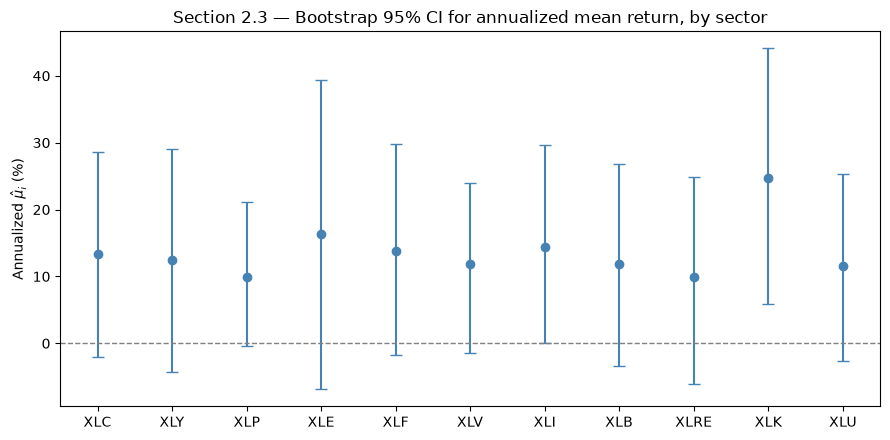

In [14]:
ci_lo = mu_boot_df.quantile(0.025) * 252 * 100
ci_hi = mu_boot_df.quantile(0.975) * 252 * 100
ci_mid = mu_boot_df.mean() * 252 * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
order = np.arange(len(SECTOR_TICKERS))
ax.errorbar(order, ci_mid, yerr=[ci_mid - ci_lo, ci_hi - ci_mid],
            fmt="o", capsize=4, color="steelblue")
ax.axhline(0, color="gray", linewidth=1, linestyle="--")
ax.set_xticks(order)
ax.set_xticklabels(SECTOR_TICKERS)
ax.set_ylabel(r"Annualized $\hat{\mu}_i$ (%)")
ax.set_title("Section 2.3 — Bootstrap 95% CI for annualized mean return, by sector")
fig.tight_layout()
plt.show()

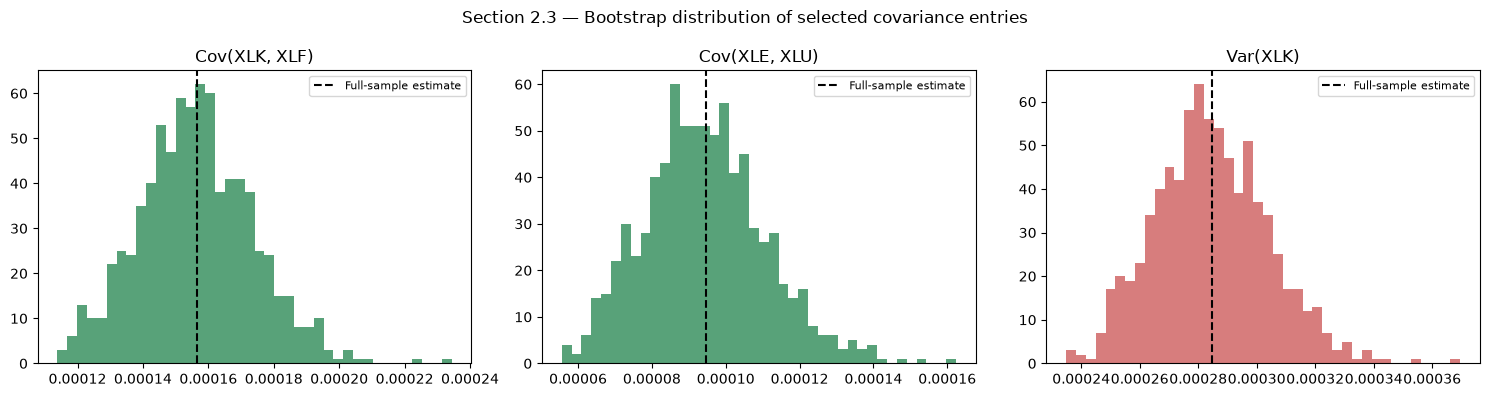

In [15]:
pairs = [("XLK", "XLF"), ("XLE", "XLU")]
fig, axes = plt.subplots(1, len(pairs) + 1, figsize=(15, 4))
for ax, (a, b) in zip(axes, pairs):
    ia, ib = SECTOR_TICKERS.index(a), SECTOR_TICKERS.index(b)
    ax.hist(Sigma_boot[:, ia, ib], bins=40, color="seagreen", alpha=0.8)
    ax.axvline(sample_Sigma.loc[a, b], color="black", linestyle="--", label="Full-sample estimate")
    ax.set_title(f"Cov({a}, {b})")
    ax.legend(fontsize=8)

ik = SECTOR_TICKERS.index("XLK")
axes[-1].hist(Sigma_boot[:, ik, ik], bins=40, color="indianred", alpha=0.8)
axes[-1].axvline(sample_Sigma.loc["XLK", "XLK"], color="black", linestyle="--", label="Full-sample estimate")
axes[-1].set_title("Var(XLK)")
axes[-1].legend(fontsize=8)

fig.suptitle("Section 2.3 — Bootstrap distribution of selected covariance entries")
fig.tight_layout()
plt.show()

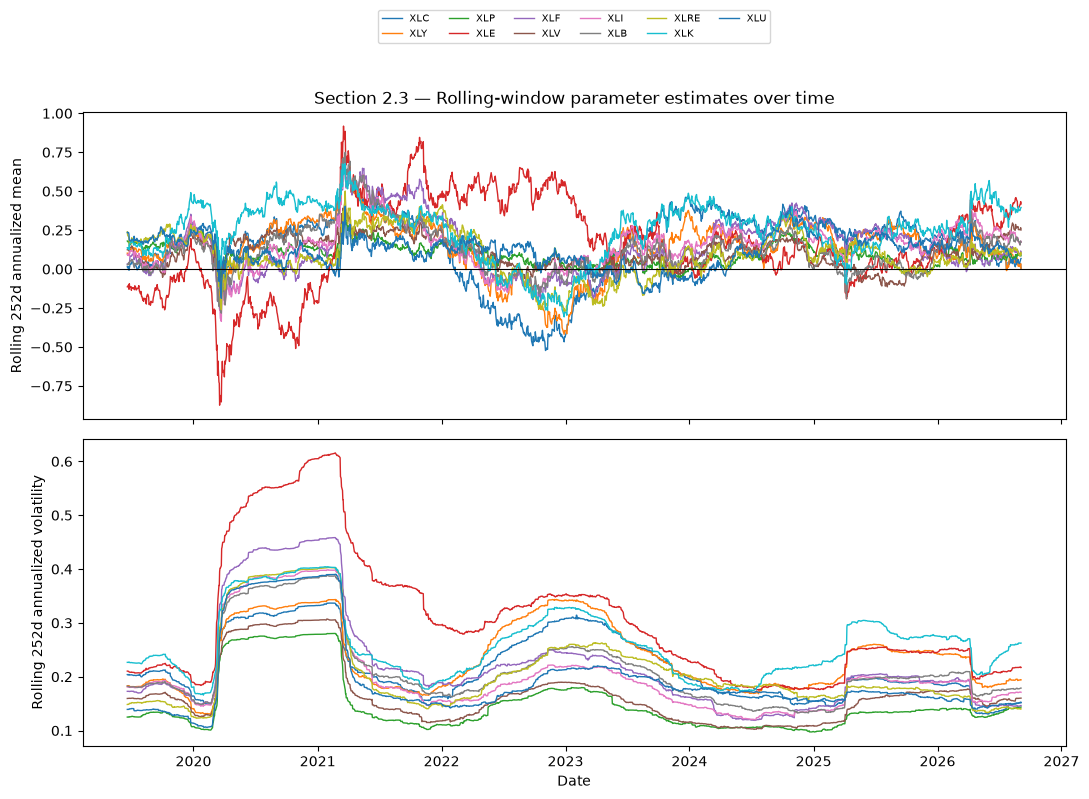

In [16]:
ROLL_WINDOW = 252
rolling_mu = returns[SECTOR_TICKERS].rolling(ROLL_WINDOW).mean().dropna() * 252
rolling_vol = (returns[SECTOR_TICKERS].rolling(ROLL_WINDOW).std() * np.sqrt(252)).dropna()
rolling_cov = returns[SECTOR_TICKERS].rolling(ROLL_WINDOW).cov().dropna()

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for ticker in SECTOR_TICKERS:
    axes[0].plot(rolling_mu.index, rolling_mu[ticker], label=ticker, linewidth=1)
    axes[1].plot(rolling_vol.index, rolling_vol[ticker], label=ticker, linewidth=1)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylabel("Rolling 252d annualized mean")
axes[1].set_ylabel("Rolling 252d annualized volatility")
axes[1].set_xlabel("Date")
axes[0].set_title("Section 2.3 — Rolling-window parameter estimates over time")
axes[0].legend(ncol=6, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, 1.35))
fig.tight_layout()
plt.show()

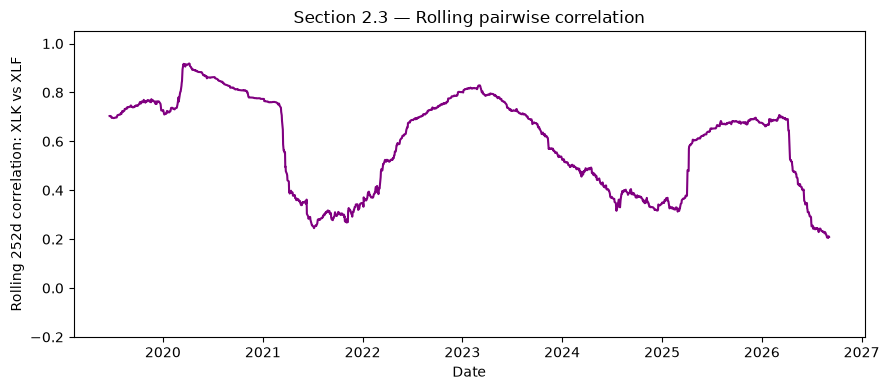

In [17]:
pair_a, pair_b = "XLK", "XLF"
rolling_corr_pair = rolling_cov.xs(pair_a, level=1)[pair_b] / (
    rolling_vol[pair_a] / np.sqrt(252) * rolling_vol[pair_b] / np.sqrt(252)
)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(rolling_corr_pair.index, rolling_corr_pair.values, color="purple")
ax.set_ylim(-0.2, 1.05)
ax.set_ylabel(f"Rolling 252d correlation: {pair_a} vs {pair_b}")
ax.set_xlabel("Date")
ax.set_title("Section 2.3 — Rolling pairwise correlation")
fig.tight_layout()
plt.show()

**Interpretation (2.3).** Several sectors 95% CI bands comfortably straddle zero, reinforcing 2.1's finding that mean returns are hard to get correct. By contrast, the bootstrap distributions of individual covariance entries are tight and symmetric around the full-sample estimate. The rolling-window plots reveal clear regimes rather than stationary estimates. The sharp mean and volatility spike visible in the top panels around 2020 corresponds to the COVID-19 crash, with another spike likely coming from the start of the Iran War & associated economic damages from that event. Rolling volatility estimates move in clearly identifiable, persistent regimes, while rolling mean estimates are far noisier and cross zero repeatedly for most sectors. The rolling XLK–XLF correlation plot shows correlation itself is not remotely constant over time.

### 2.4 — Dimension vs. Sample Size: When the Universe Outgrows the Data

Fix $n=252$ throughout this subsection and fit a synthetic one-factor ground truth for $k > 12$ using the *empirical distribution* of the alphas, betas, and idiosyncratic variances estimated for the 11 real sectors. Betas and alphas are drawn from a normal distribution matched to the mean/std of the 11 real values; idiosyncratic variances are drawn from a lognormal distribution matched to the mean/std of $\log(\hat\sigma^2_{\varepsilon,i})$ across the 11 real sectors.

In [18]:
GAMMA_BASE = 5.0  # a representative moderate risk-aversion level, reused below and in Sections 3 and 5

beta_mean, beta_std = betas.mean(), betas.std()
alpha_mean, alpha_std = alphas.mean(), alphas.std()
log_resid_var_mean = np.log(resid_vars).mean()
log_resid_var_std = np.log(resid_vars).std()

K_GRID = [5, 12, 50, 150, 252, 400]
N_FIXED_24 = 252
N_SIMS_24 = 150
rng24 = np.random.default_rng(RNG_SEED)


def ground_truth_for_k(k, rng):
    if k <= K_FULL:
        return mu_star_full[:k], Sigma_star_full[:k, :k]
    beta_k = rng.normal(beta_mean, beta_std, size=k)
    alpha_k = rng.normal(alpha_mean, alpha_std, size=k)
    idio_var_k = np.exp(rng.normal(log_resid_var_mean, log_resid_var_std, size=k))
    mu_k = alpha_k + beta_k * market_mean
    Sigma_k = np.diag(idio_var_k) + np.outer(beta_k, beta_k) * market_var
    return mu_k, Sigma_k


rows = []
for k in K_GRID:
    mu_k, Sigma_k = ground_truth_for_k(k, rng24)
    samples = rng24.multivariate_normal(mu_k, Sigma_k, size=(N_SIMS_24, N_FIXED_24))
    mu_hats = samples.mean(axis=1)
    centered = samples - mu_hats[:, None, :]
    Sigma_hats = np.einsum("sik,sil->skl", centered, centered) / (N_FIXED_24 - 1)

    for s in range(N_SIMS_24):
        Sh, mh = Sigma_hats[s], mu_hats[s]
        cond = np.linalg.cond(Sh)
        min_eig = np.linalg.eigvalsh(Sh)[0]
        try:
            w = np.linalg.solve(Sh, mh) / GAMMA_BASE
        except np.linalg.LinAlgError:
            w = np.linalg.pinv(Sh) @ mh / GAMMA_BASE
        rows.append(dict(k=k, cond=cond, min_eig=min_eig,
                          w_l2=np.linalg.norm(w), gross_leverage=np.abs(w).sum()))

results_24 = pd.DataFrame(rows)
results_24.groupby("k")[["cond", "min_eig", "w_l2", "gross_leverage"]].median()

,cond,min_eig,w_l2,gross_leverage
k,,,,
5,2.085102e+01,3.670877e-05,2.915322e+00,5.508338e+00
12,1.590053e+03,1.025988e-06,1.047174e+01,2.691138e+01
50,4.144666e+02,1.532615e-05,1.470205e+01,8.012128e+01
150,6.199129e+03,2.947653e-06,8.146960e+01,7.758864e+02
252,4.739572e+17,-1.544596e-21,1.326271e+15,1.638593e+16
400,2.275239e+19,-3.253049e-18,3.804499e+16,5.894270e+17


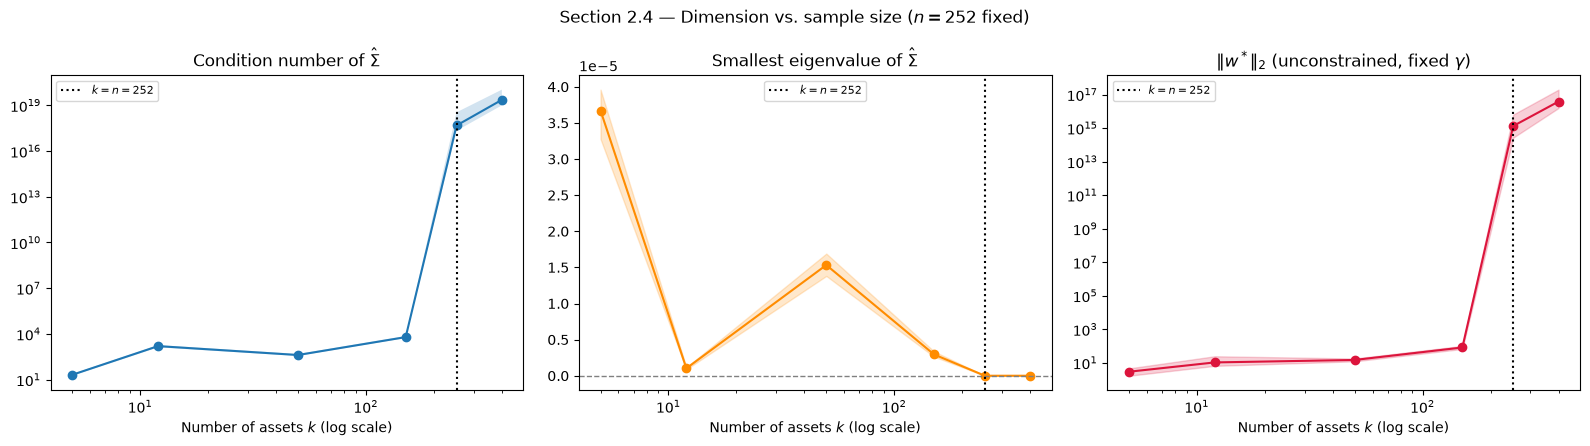

In [19]:
summary_24 = results_24.groupby("k").agg(
    cond_med=("cond", "median"), cond_lo=("cond", lambda x: x.quantile(0.1)), cond_hi=("cond", lambda x: x.quantile(0.9)),
    eig_med=("min_eig", "median"), eig_lo=("min_eig", lambda x: x.quantile(0.1)), eig_hi=("min_eig", lambda x: x.quantile(0.9)),
    w_med=("w_l2", "median"), w_lo=("w_l2", lambda x: x.quantile(0.1)), w_hi=("w_l2", lambda x: x.quantile(0.9)),
).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(summary_24["k"], summary_24["cond_med"], marker="o")
axes[0].fill_between(summary_24["k"], summary_24["cond_lo"], summary_24["cond_hi"], alpha=0.2)
axes[0].set_yscale("log")
axes[0].set_xscale("log")
axes[0].set_title(r"Condition number of $\hat\Sigma$")

axes[1].plot(summary_24["k"], summary_24["eig_med"], marker="o", color="darkorange")
axes[1].fill_between(summary_24["k"], summary_24["eig_lo"], summary_24["eig_hi"], alpha=0.2, color="darkorange")
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set_xscale("log")
axes[1].set_title(r"Smallest eigenvalue of $\hat\Sigma$")

axes[2].plot(summary_24["k"], summary_24["w_med"], marker="o", color="crimson")
axes[2].fill_between(summary_24["k"], summary_24["w_lo"], summary_24["w_hi"], alpha=0.2, color="crimson")
axes[2].set_yscale("log")
axes[2].set_xscale("log")
axes[2].set_title(r"$\|w^*\|_2$ (unconstrained, fixed $\gamma$)")

for ax in axes:
    ax.axvline(N_FIXED_24, color="black", linestyle=":", linewidth=1.5, label="$k = n = 252$")
    ax.set_xlabel("Number of assets $k$ (log scale)")
    ax.legend(fontsize=8)
fig.suptitle("Section 2.4 — Dimension vs. sample size ($n=252$ fixed)")
fig.tight_layout()
plt.show()

**Interpretation (2.4).** All three quantities move together exactly as the theory predicts. As $k$ approaches $n=252$, the smallest eigenvalue of $\hat{\boldsymbol{\Sigma}}$ is driven toward zero and the condition number explodes. Once $k$ exceeds $n$, $\hat{\boldsymbol{\Sigma}}$ is mathematically rank-deficient (rank $\le n < k$), so its smallest eigenvalue is numerically at or below zero and its condition number becomes enormous. It is a consequence of asking $n$ data points to pin down $k(k+1)/2$ covariance parameters. Because $\mathbf{w}^* \propto \hat{\boldsymbol{\Sigma}}^{-1}\hat{\boldsymbol{\mu}}$, inverting a near-singular matrix means dividing by numbers close to zero along the eigen-directions, which is  what makes $\|\mathbf{w}^*\|_2$ blow up. 

## Section 3 — How Uncertainty in Parameters Propagates to Weights

The **sample-moment** estimates from Section 2.2 ($\hat{\boldsymbol{\mu}}$ = `sample_mu`, $\hat{\boldsymbol{\Sigma}}$ = `sample_Sigma`, both over the 11 sector ETFs) as the single fixed reference point for this entire section.

In [20]:
def mv_weights(mu, Sigma, gamma):
    """Closed-form unconstrained mean-variance weights: w* = (1/gamma) Sigma^-1 mu."""
    return np.linalg.solve(Sigma, mu) / gamma


base_mu = sample_mu.to_numpy()
base_Sigma = sample_Sigma.to_numpy()
base_D = np.sqrt(np.diag(base_Sigma))
base_C = base_Sigma / np.outer(base_D, base_D)

### 3.1 — Sensitivity to $\gamma$

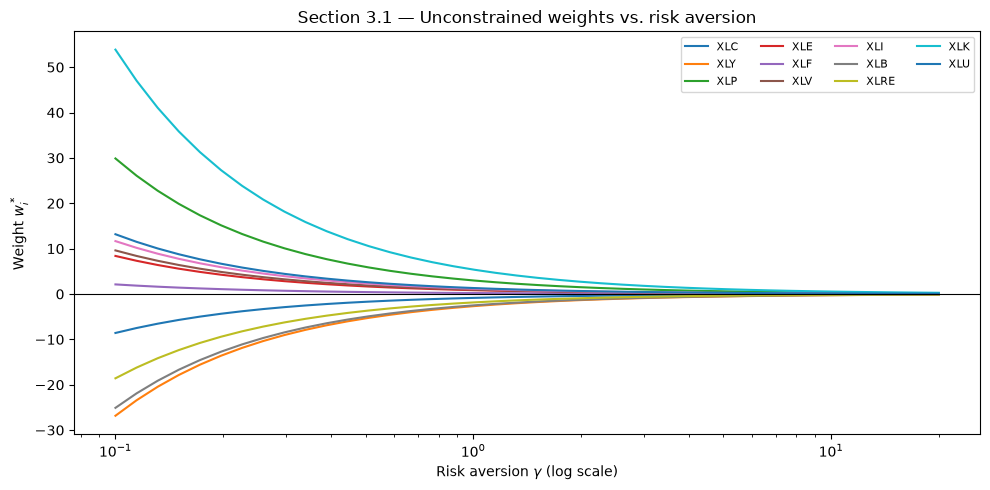

Gross leverage at gamma=0.1: 207.8
Gross leverage at gamma=20:  1.04
Smallest gamma with gross leverage <= 2.0: 11.62


In [21]:
gamma_grid = np.logspace(np.log10(0.1), np.log10(20), 40)
weights_by_gamma = np.array([mv_weights(base_mu, base_Sigma, g) for g in gamma_grid])

fig, ax = plt.subplots(figsize=(10, 5))
for j, ticker in enumerate(SECTOR_TICKERS):
    ax.plot(gamma_grid, weights_by_gamma[:, j], label=ticker)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xscale("log")
ax.set_xlabel(r"Risk aversion $\gamma$ (log scale)")
ax.set_ylabel(r"Weight $w_i^*$")
ax.set_title("Section 3.1 — Unconstrained weights vs. risk aversion")
ax.legend(ncol=4, fontsize=8)
fig.tight_layout()
plt.show()

gross_leverage_by_gamma = np.abs(weights_by_gamma).sum(axis=1)
reasonable_gamma = gamma_grid[gross_leverage_by_gamma <= 2.0]
print(f"Gross leverage at gamma=0.1: {gross_leverage_by_gamma[0]:.1f}")
print(f"Gross leverage at gamma=20:  {gross_leverage_by_gamma[-1]:.2f}")
print(f"Smallest gamma with gross leverage <= 2.0: "
      f"{reasonable_gamma.min():.2f}" if len(reasonable_gamma) else "never under 2.0 on this grid")

**Interpretation (3.1).** At very low $\gamma$  the optimizer is  risk-indifferent and chases the noisy $\hat{\boldsymbol{\mu}}$ estimates aggressively, producing extreme positions. As $\gamma$ increases, weights shrink toward zero, and the portfolio only becomes reasonable once $\gamma$ is large enough to bring gross leverage down near 1–2. 

### 3.2 — Sensitivity to $\boldsymbol{\mu}$

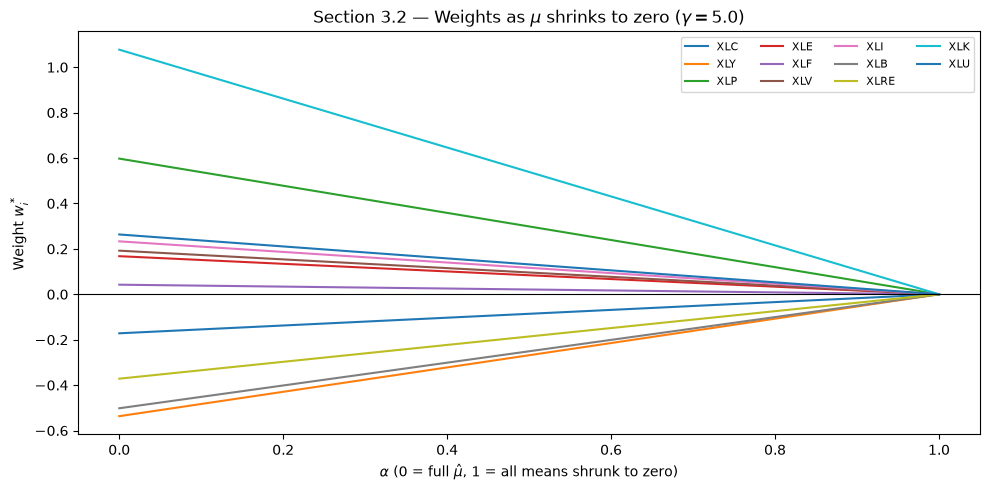

Gross leverage at alpha=0: 4.16
Gross leverage at alpha=1 (all means zero): 0.00
Smallest alpha with gross leverage <= 1.5: 0.64


In [22]:
alpha_grid = np.linspace(0, 1, 40)
weights_by_alpha = np.array([
    mv_weights((1 - a) * base_mu, base_Sigma, GAMMA_BASE) for a in alpha_grid
])

fig, ax = plt.subplots(figsize=(10, 5))
for j, ticker in enumerate(SECTOR_TICKERS):
    ax.plot(alpha_grid, weights_by_alpha[:, j], label=ticker)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel(r"$\alpha$ (0 = full $\hat\mu$, 1 = all means shrunk to zero)")
ax.set_ylabel(r"Weight $w_i^*$")
ax.set_title(rf"Section 3.2 — Weights as $\mu$ shrinks to zero ($\gamma={GAMMA_BASE}$)")
ax.legend(ncol=4, fontsize=8)
fig.tight_layout()
plt.show()

gross_leverage_by_alpha = np.abs(weights_by_alpha).sum(axis=1)
well_behaved = alpha_grid[gross_leverage_by_alpha <= 1.5]
print(f"Gross leverage at alpha=0: {gross_leverage_by_alpha[0]:.2f}")
print(f"Gross leverage at alpha=1 (all means zero): {gross_leverage_by_alpha[-1]:.2f}")
print(f"Smallest alpha with gross leverage <= 1.5: "
      f"{well_behaved.min():.2f}" if len(well_behaved) else "never under 1.5")

**Interpretation (3.2).** Weights shrink roughly linearly toward the minimum solution as $\alpha \to 1$, since at $\alpha=1$ the objective is driven purely by $\hat{\boldsymbol{\Sigma}}^{-1}$ with no return signal at all. The weights become comfortably 'well-behaved' with leverage near 1 before $\alpha=1$. The large share of the unconstrained portfolio's aggressiveness at $\alpha=0$ is attributable to how much weight the optimizer places on our noisy $\hat{\boldsymbol{\mu}}$.

### 3.3 — Sensitivity to Correlations

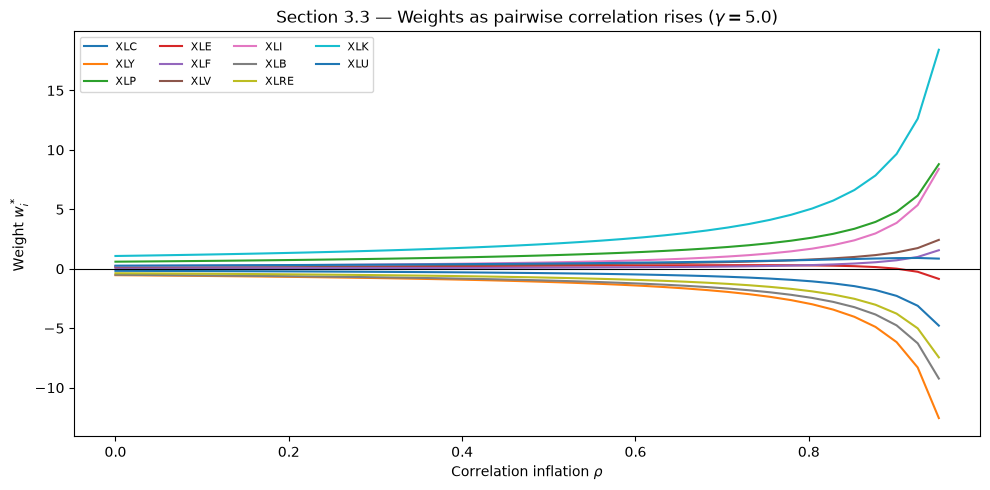

Gross leverage at rho=0:    4.16
Gross leverage at rho=0.95: 75.33


In [23]:
rho_grid = np.linspace(0, 0.95, 40)
k_sectors = len(SECTOR_TICKERS)
ones_mat = np.ones((k_sectors, k_sectors)) / k_sectors

weights_by_rho = []
for rho in rho_grid:
    C_rho = (1 - rho) * base_C + rho * ones_mat
    Sigma_rho = np.outer(base_D, base_D) * C_rho
    weights_by_rho.append(mv_weights(base_mu, Sigma_rho, GAMMA_BASE))
weights_by_rho = np.array(weights_by_rho)

fig, ax = plt.subplots(figsize=(10, 5))
for j, ticker in enumerate(SECTOR_TICKERS):
    ax.plot(rho_grid, weights_by_rho[:, j], label=ticker)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel(r"Correlation inflation $\rho$")
ax.set_ylabel(r"Weight $w_i^*$")
ax.set_title(rf"Section 3.3 — Weights as pairwise correlation rises ($\gamma={GAMMA_BASE}$)")
ax.legend(ncol=4, fontsize=8)
fig.tight_layout()
plt.show()

gross_leverage_by_rho = np.abs(weights_by_rho).sum(axis=1)
print(f"Gross leverage at rho=0:    {gross_leverage_by_rho[0]:.2f}")
print(f"Gross leverage at rho=0.95: {gross_leverage_by_rho[-1]:.2f}")

**Interpretation (3.3).** As $\rho \to 1$, the correlation matrix $\mathbf{C}(\rho)$ approaches a every asset moving together, so $\boldsymbol{\Sigma}(\rho)$ becomes increasingly ill-conditioned. The diversification benefit vanishes because there is effectively only one independent source of risk left. The optimizer responds by taking increasingly large, offsetting long/short positions to try to extract a diversification-like benefit from assets that are no longer meaningfully diversifying. 

### 3.4 — Sensitivity to Volatility

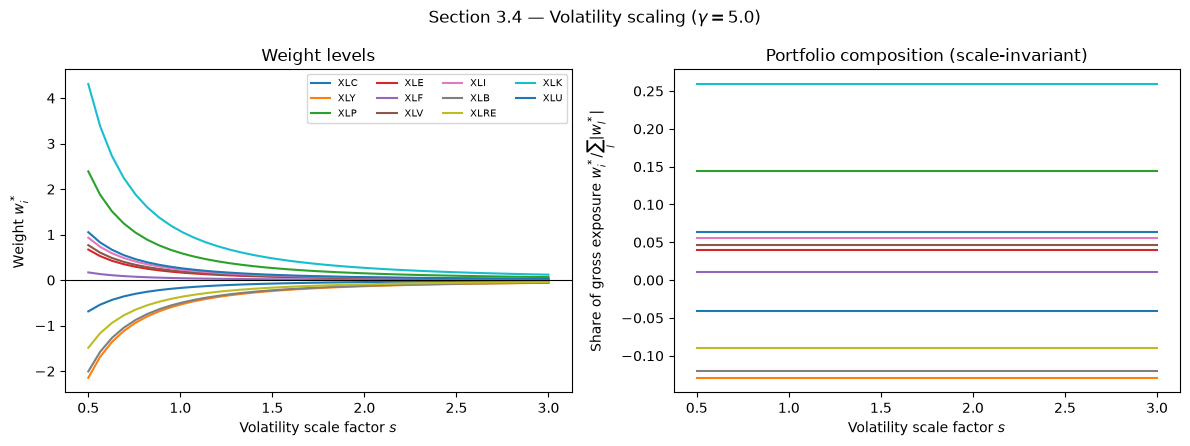

Max change in composition share across s grid: 0.0000


In [24]:
s_grid = np.linspace(0.5, 3.0, 40)
weights_by_s = np.array([
    mv_weights(base_mu, np.outer(s * base_D, s * base_D) * base_C, GAMMA_BASE)
    for s in s_grid
])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for j, ticker in enumerate(SECTOR_TICKERS):
    axes[0].plot(s_grid, weights_by_s[:, j], label=ticker)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Volatility scale factor $s$")
axes[0].set_ylabel(r"Weight $w_i^*$")
axes[0].set_title("Weight levels")
axes[0].legend(ncol=4, fontsize=7)

weight_shares = weights_by_s / np.abs(weights_by_s).sum(axis=1, keepdims=True)
for j, ticker in enumerate(SECTOR_TICKERS):
    axes[1].plot(s_grid, weight_shares[:, j], label=ticker)
axes[1].set_xlabel("Volatility scale factor $s$")
axes[1].set_ylabel(r"Share of gross exposure $w_i^* / \sum_l|w_l^*|$")
axes[1].set_title("Portfolio composition (scale-invariant)")

fig.suptitle(rf"Section 3.4 — Volatility scaling ($\gamma={GAMMA_BASE}$)")
fig.tight_layout()
plt.show()

print("Max change in composition share across s grid:",
      f"{(weight_shares.max(axis=0) - weight_shares.min(axis=0)).max():.4f}")

**Interpretation (3.4).** Because it scales every entry of $\boldsymbol{\Sigma}$ by the same factor $s^2$, the closed-form $\mathbf{w}^*(s) = \frac{1}{\gamma s^2}\boldsymbol{\Sigma}^{-1}\boldsymbol{\mu}$ shrinks uniformly as $s$ grows. Every position gets smaller, but by the same proportion. The left panel shows the overall scale collapsing as $s$ rises; the right panel, which normalizes by gross exposure, shows the composition barely moves at all. Scaling volatility up or down changes how much risk the optimizer is willing to take in total.

### 3.5 — A Dose of Realism: Constrained Weights

**Two** constraints on top of the base mean-variance objective, each solved with `scipy.optimize.minimize` (SLSQP) since neither has a simple closed form: **long-only** ($w_i \ge 0$) and a **gross-leverage cap** ($\sum_i |w_i| \le L$.

In [25]:
from scipy.optimize import minimize


def neg_utility(w, mu, Sigma, gamma):
    return -(w @ mu - 0.5 * gamma * w @ Sigma @ w)


w_unconstrained = mv_weights(base_mu, base_Sigma, GAMMA_BASE)
u_unconstrained = -neg_utility(w_unconstrained, base_mu, base_Sigma, GAMMA_BASE)

# Long-only
res_long_only = minimize(
    neg_utility, x0=np.ones(k_sectors) / k_sectors, args=(base_mu, base_Sigma, GAMMA_BASE),
    method="SLSQP", bounds=[(0, None)] * k_sectors,
)
w_long_only = res_long_only.x
u_long_only = -res_long_only.fun

# Gross leverage cap (L = 1.5)
L_CAP = 1.5
res_lev = minimize(
    neg_utility, x0=w_unconstrained / max(1.0, np.abs(w_unconstrained).sum() / L_CAP),
    args=(base_mu, base_Sigma, GAMMA_BASE), method="SLSQP",
    constraints=[{"type": "ineq", "fun": lambda w: L_CAP - np.sum(np.abs(w))}],
)
w_lev_capped = res_lev.x
u_lev_capped = -res_lev.fun

comparison = pd.DataFrame({
    "Unconstrained": w_unconstrained,
    "Long-only": w_long_only,
    f"Leverage <= {L_CAP}": w_lev_capped,
}, index=SECTOR_TICKERS)
comparison.loc["Gross leverage"] = comparison.abs().sum()
comparison.loc["Utility"] = [u_unconstrained, u_long_only, u_lev_capped]
comparison.round(3)

,Unconstrained,Long-only,Leverage <= 1.5
XLC,-0.172,0.091,0.000
XLY,-0.537,0.091,-0.134
XLP,0.597,0.091,0.233
XLE,0.168,0.091,0.097
XLF,0.042,0.091,0.045
XLV,0.192,0.091,0.092
XLI,0.233,0.091,0.116
XLB,-0.502,0.091,-0.125
XLRE,-0.372,0.091,-0.084
XLK,1.077,0.091,0.457


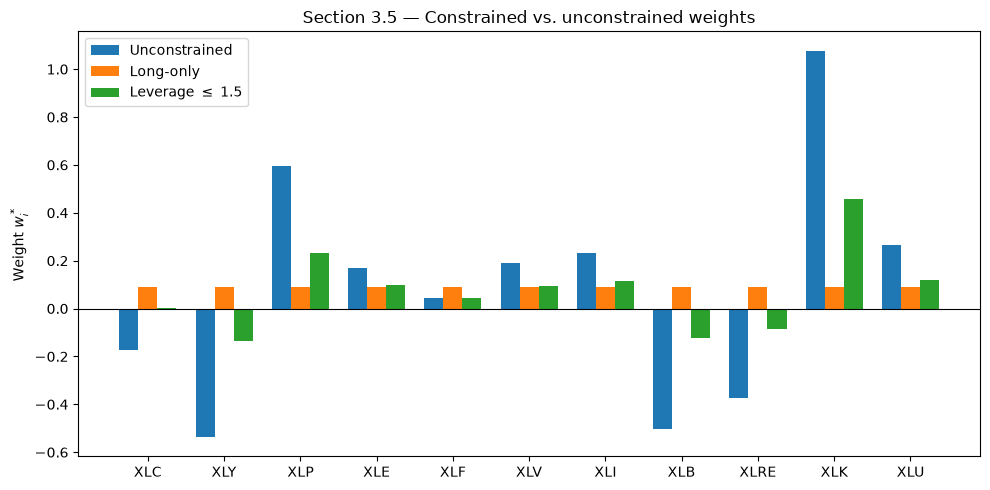

Utility given up (long-only):        0.000302 (58.1% of unconstrained utility)
Utility given up (leverage <= 1.5): 0.000121 (23.3% of unconstrained utility)


In [26]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(k_sectors)
width = 0.25
ax.bar(x - width, w_unconstrained, width, label="Unconstrained")
ax.bar(x, w_long_only, width, label="Long-only")
ax.bar(x + width, w_lev_capped, width, label=f"Leverage $\\leq$ {L_CAP}")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(SECTOR_TICKERS)
ax.set_ylabel(r"Weight $w_i^*$")
ax.set_title("Section 3.5 — Constrained vs. unconstrained weights")
ax.legend()
fig.tight_layout()
plt.show()

print(f"Utility given up (long-only):        {u_unconstrained - u_long_only:.6f} "
      f"({(u_unconstrained - u_long_only) / abs(u_unconstrained) * 100:.1f}% of unconstrained utility)")
print(f"Utility given up (leverage <= {L_CAP}): {u_unconstrained - u_lev_capped:.6f} "
      f"({(u_unconstrained - u_lev_capped) / abs(u_unconstrained) * 100:.1f}% of unconstrained utility)")

**Interpretation (3.5).** Both constraints bind, and both give up some mean-variance utility relative to the unconstrained optimum. The long-only constraint eliminates every negative bar in the plot by, redistributing capital toward the sectors the optimizer still likes best. The leverage cap keeps some short positions but scales the whole portfolio down towards the budget. In both cases the utility given up is the price of insuring against exactly the fragility Sections 2.4 and 3.1–3.3 demonstrated — a small, quantifiable cost for a portfolio that is dramatically less sensitive to estimation error in $\hat{\boldsymbol{\mu}}$ and $\hat{\boldsymbol{\Sigma}}$.

## Section 4 — The Effect of Rebalancing and Trading Costs

**Sample-moment** estimates throughout this section (the CAPM comparison was explored for its own sake in Section 2.2 but isn't used downstream, so the estimation approach stays consistent across Sections 3–5). Also set the **risk-free rate to zero** throughout.

In [27]:
RF_ANNUAL = 0.0

n_total = len(returns)
split_idx = int(n_total * 0.6)
train_returns = returns.iloc[:split_idx]
test_returns = returns.iloc[split_idx:]

print(f"Train: {train_returns.index.min().date()} to {train_returns.index.max().date()} "
      f"({len(train_returns)} days)")
print(f"Test:  {test_returns.index.min().date()} to {test_returns.index.max().date()} "
      f"({len(test_returns)} days)")

Train: 2018-06-20 to 2023-05-19 (1238 days)
Test:  2023-05-22 to 2026-09-04 (826 days)


In [28]:
mu_train = train_returns[SECTOR_TICKERS].mean().to_numpy()
Sigma_train = train_returns[SECTOR_TICKERS].cov().to_numpy()
w_star_train = mv_weights(mu_train, Sigma_train, GAMMA_BASE)

pd.Series(w_star_train, index=SECTOR_TICKERS, name="w*_train").round(3)

XLC    -0.902
XLY    -0.389
XLP     0.817
XLE     0.189
XLF    -0.345
XLV     0.075
XLI    -0.070
XLB    -0.044
XLRE   -0.351
XLK     1.515
XLU     0.122
Name: w*_train, dtype: float64

In [29]:
def compute_metrics(returns, rf_annual=RF_ANNUAL, periods_per_year=252):
    """Standard performance metrics from a series of simple daily returns."""
    returns = np.asarray(returns)
    wealth = np.cumprod(1 + returns)
    n = len(returns)
    total_return = wealth[-1] - 1
    ann_return = (1 + total_return) ** (periods_per_year / n) - 1
    ann_vol = returns.std(ddof=1) * np.sqrt(periods_per_year)
    sharpe = (returns.mean() * periods_per_year - rf_annual) / ann_vol
    running_max = np.maximum.accumulate(wealth)
    drawdown = wealth / running_max - 1
    return dict(cum_return=total_return, ann_return=ann_return,
                ann_vol=ann_vol, sharpe=sharpe, max_drawdown=drawdown.min())

### 4.1 — Frictionless Rebalancing

In [30]:
test_sector_returns = test_returns[SECTOR_TICKERS].to_numpy()
test_spy_returns = test_returns[MARKET_TICKER].to_numpy()
ew_weights = np.ones(len(SECTOR_TICKERS)) / len(SECTOR_TICKERS)

model_returns_41 = test_sector_returns @ w_star_train
ew_returns_41 = test_sector_returns @ ew_weights
spy_returns_41 = test_spy_returns

metrics_41 = pd.DataFrame({
    "Model (w*)": compute_metrics(model_returns_41),
    "Equal-weight": compute_metrics(ew_returns_41),
    "SPY": compute_metrics(spy_returns_41),
}).T
metrics_41.columns = ["Cumulative return", "Annualized return", "Annualized vol",
                       "Sharpe", "Max drawdown"]
metrics_41.round(4)

,Cumulative return,Annualized return,Annualized vol,Sharpe,Max drawdown
Model (w*),0.6959,0.1749,0.2672,0.7366,-0.3467
Equal-weight,0.6688,0.1691,0.1217,1.3447,-0.1530
SPY,0.9168,0.2196,0.1497,1.4009,-0.1876


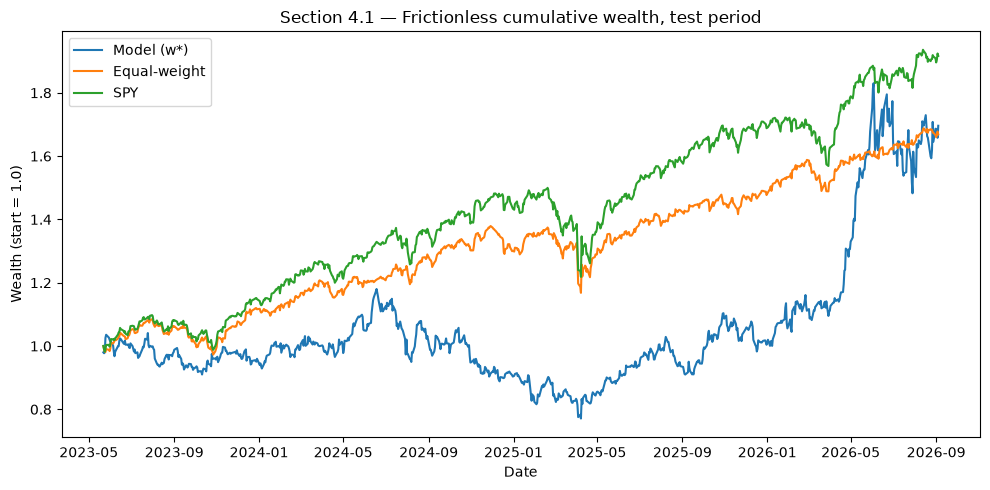

In [31]:
fig, ax = plt.subplots(figsize=(10, 5))
for label, r in [("Model (w*)", model_returns_41), ("Equal-weight", ew_returns_41), ("SPY", spy_returns_41)]:
    wealth = np.cumprod(1 + r)
    ax.plot(test_returns.index, wealth, label=label)
ax.set_xlabel("Date")
ax.set_ylabel("Wealth (start = 1.0)")
ax.set_title("Section 4.1 — Frictionless cumulative wealth, test period")
ax.legend()
fig.tight_layout()
plt.show()

**Interpretation (4.1).** The metrics table above compares the trained mean-variance portfolio to both passive benchmarks over the same frictionless test period. The two models do not pass the SPY. Equal weight has slightly lower volatility, but in general SPY is better. 

### 4.2 — Introducing Transaction Costs

In [32]:
def rebalance_schedule(dates, freq):
    """Boolean array: True on the first trading day of each period.
    Note: PeriodIndex.shift() shifts by *frequency* (adds a period), not by
    array position, so we wrap in a Series to get a positional lag-1 compare."""
    periods = pd.Series(pd.DatetimeIndex(dates).to_period(
        {"daily": "D", "weekly": "W", "monthly": "M", "quarterly": "Q"}[freq]
    ))
    return np.asarray(periods.ne(periods.shift(1)))


def backtest_fixed_target(simple_returns, target_weights, rebalance_mask,
                           cost_bps, fee_bps):
    """Simulate holding `target_weights`, rebalancing only on flagged days,
    with proportional turnover costs and a daily management-fee haircut."""
    n_days, k = simple_returns.shape
    w_drifted = target_weights.copy()
    net_returns = np.zeros(n_days)
    turnovers = np.zeros(n_days)
    costs = np.zeros(n_days)
    daily_fee = fee_bps / 1e4 / 252

    for t in range(n_days):
        if rebalance_mask[t]:
            turnover = np.abs(target_weights - w_drifted).sum()
            cost = cost_bps / 1e4 * turnover
            turnovers[t] = turnover
            costs[t] = cost
            w_used = target_weights
        else:
            w_used = w_drifted

        r_t = simple_returns[t]
        gross_port_r = w_used @ r_t
        net_returns[t] = (1 - costs[t]) * (1 + gross_port_r) - 1 - daily_fee

        # Renormalize by (1 + portfolio return), NOT sum(new_val): the weights
        # need not sum to 1 (this is an unconstrained long/short portfolio with
        # an implicit cash/leverage leg), so dividing by sum(new_val) would
        # silently force the book back toward full investment every day and
        # manufacture phantom turnover.
        new_val = w_used * (1 + r_t)
        w_drifted = new_val / (1 + gross_port_r)

    return net_returns, turnovers, costs

In [33]:
FEE_BPS = 50.0  # 0.50%/year fixed management fee, held constant across this sweep
FREQUENCIES = ["daily", "weekly", "monthly", "quarterly"]
COST_LEVELS_BPS = [1, 5, 10, 20]

sweep_rows = []
for freq in FREQUENCIES:
    mask = rebalance_schedule(test_returns.index, freq)
    for c in COST_LEVELS_BPS:
        net_r, turnover, cost = backtest_fixed_target(
            test_sector_returns, w_star_train, mask, cost_bps=c, fee_bps=FEE_BPS
        )
        m = compute_metrics(net_r)
        sweep_rows.append(dict(frequency=freq, cost_bps=c, sharpe=m["sharpe"],
                                ann_return=m["ann_return"], ann_turnover=turnover.sum() * 252 / len(turnover)))

sweep_42 = pd.DataFrame(sweep_rows)
sweep_42.pivot(index="frequency", columns="cost_bps", values="sharpe").loc[FREQUENCIES]

cost_bps,1,5,10,20
frequency,,,,
daily,0.712003,0.688491,0.659102,0.600330
weekly,0.734308,0.724221,0.711608,0.686371
monthly,0.733649,0.728743,0.722608,0.710330
quarterly,0.748838,0.745865,0.742146,0.734705


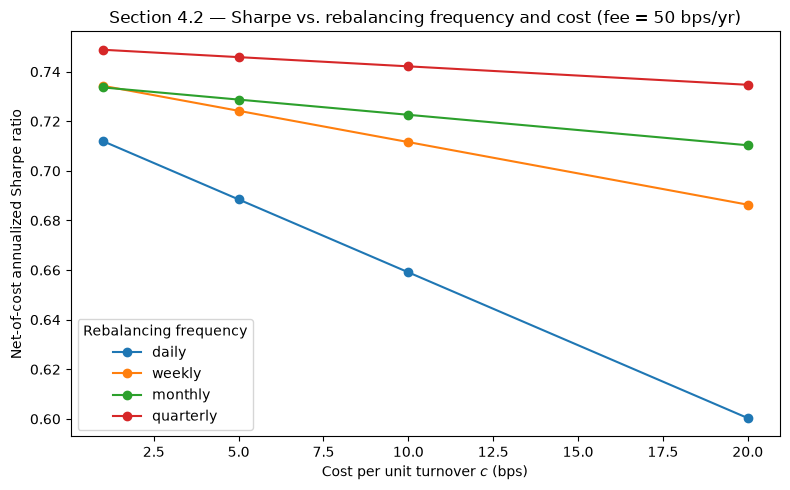

Annualized turnover by frequency (at c=10bps):
frequency
daily        15.69
weekly        6.75
monthly       3.26
quarterly     1.93
Name: ann_turnover, dtype: float64


In [34]:
fig, ax = plt.subplots(figsize=(8, 5))
for freq in FREQUENCIES:
    sub = sweep_42[sweep_42["frequency"] == freq]
    ax.plot(sub["cost_bps"], sub["sharpe"], marker="o", label=freq)
ax.set_xlabel("Cost per unit turnover $c$ (bps)")
ax.set_ylabel("Net-of-cost annualized Sharpe ratio")
ax.set_title(f"Section 4.2 — Sharpe vs. rebalancing frequency and cost (fee = {FEE_BPS:.0f} bps/yr)")
ax.legend(title="Rebalancing frequency")
fig.tight_layout()
plt.show()

print("Annualized turnover by frequency (at c=10bps):")
print(sweep_42[sweep_42["cost_bps"] == 10].set_index("frequency")["ann_turnover"].round(2))

**Interpretation (4.2).** Because the target is fixed for the entire test period in this section, frequent rebalancing here buys only a modest benefit while still paying turnover cost for it. With this particular $\mathbf{w}^*$, quarterly rebalancing wins at every cost level tested. The annualized turnover figures explain why, daily and weekly are paying for tracking precision this static target doesn't reward. The Sharpe-ratio gap between quarterly and monthly widens as $c$ rises, so while the ranking of frequencies doesn't flip here, how much it matters to pick the least-frequent option does depend on $c$. 

## Section 5 — Full Backtester

### 5.1 — The Loop

**Expanding vs. rolling window.**  An **expanding window**: at each step $t$, $\hat{\boldsymbol{\mu}}_t$ and $\hat{\boldsymbol{\Sigma}}_t$ are estimated from all returns available through day $t$, rather than a fixed trailing window. Only about 8 years of common history across all 11 sectors, so a rolling window would either have to be short and noisy, or would need to discard a large share of our already-limited history. The expanding window trades some adaptivity for lower estimation variance, which judged to be the more valuable trade given how little history there is to begin with.

In [35]:
sector_returns_df = returns[SECTOR_TICKERS]
sector_arr = sector_returns_df.to_numpy()
dates_all = sector_returns_df.index
T_FULL = len(dates_all)
T0 = 252  # one year of burn-in before the first estimate

BACKTEST_COST_BPS = 10.0   # representative mid-range cost, consistent with Section 4.2
BACKTEST_FEE_BPS = 50.0    # same management fee assumption as Section 4.2

monthly_rebalance_mask = rebalance_schedule(dates_all, "monthly")


def walk_forward_backtest(weight_fn, cost_bps=BACKTEST_COST_BPS, fee_bps=BACKTEST_FEE_BPS,
                           rebalance_mask=monthly_rebalance_mask, t0=T0):
    """Expanding-window walk-forward loop. `weight_fn(mu_t, Sigma_t) -> w_t`
    is called using only data through day t; the resulting position earns day
    t+1's return (never day t's own), avoiding the classic off-by-one lookahead
    bug flagged in the assignment."""
    k = sector_arr.shape[1]
    w_drifted = np.zeros(k)
    daily_fee = fee_bps / 1e4 / 252
    out_dates, net_rets, turns, costs, weights_used = [], [], [], [], []

    for t in range(t0, T_FULL - 1):
        hist = sector_arr[: t + 1]          # data through day t only
        mu_t = hist.mean(axis=0)
        Sigma_t = np.cov(hist, rowvar=False, ddof=1)
        w_t_star = weight_fn(mu_t, Sigma_t)

        is_rebal = (t == t0) or rebalance_mask[t]
        if is_rebal:
            turnover_t = np.abs(w_t_star - w_drifted).sum()
            cost_t = cost_bps / 1e4 * turnover_t
            w_used = w_t_star
        else:
            turnover_t = 0.0
            cost_t = 0.0
            w_used = w_drifted

        r_t1 = sector_arr[t + 1]          # day t+1 return -- never day t's
        gross_r = w_used @ r_t1
        net_r = (1 - cost_t) * (1 + gross_r) - 1 - daily_fee

        w_drifted = (w_used * (1 + r_t1)) / (1 + gross_r)

        out_dates.append(dates_all[t + 1])
        net_rets.append(net_r)
        turns.append(turnover_t)
        costs.append(cost_t)
        weights_used.append(w_t_star)

    idx = pd.DatetimeIndex(out_dates, name="Date")
    perf = pd.DataFrame({"net_return": net_rets, "turnover": turns, "cost": costs}, index=idx)
    weights_df = pd.DataFrame(weights_used, index=idx, columns=SECTOR_TICKERS)
    return perf, weights_df


def mv_weight_fn(mu, Sigma):
    return mv_weights(mu, Sigma, GAMMA_BASE)


perf_5, weights_5 = walk_forward_backtest(mv_weight_fn)
print(f"Walk-forward period: {perf_5.index.min().date()} to {perf_5.index.max().date()} "
      f"({len(perf_5)} trading days)")
perf_5.head()

Walk-forward period: 2019-06-24 to 2026-09-04 (1811 trading days)


,net_return,turnover,cost
Date,,,
2019-06-24,-0.008121,10.282325,0.010282
2019-06-25,-0.020578,0.000000,0.000000
2019-06-26,-0.054919,0.000000,0.000000
2019-06-27,0.015901,0.000000,0.000000
2019-06-28,-0.025948,0.000000,0.000000


### 5.2 — Performance Report: The Tearsheet

In [36]:
m_strategy = compute_metrics(perf_5["net_return"].to_numpy())

oos_dates = perf_5.index
oos_sector_returns = sector_arr[T0 + 1:]  # perf_5 covers indices T0+1 .. T_FULL-1
oos_spy_returns = returns.loc[oos_dates, MARKET_TICKER].to_numpy()

ew_returns_oos = oos_sector_returns @ (np.ones(len(SECTOR_TICKERS)) / len(SECTOR_TICKERS))
m_ew = compute_metrics(ew_returns_oos)
m_spy = compute_metrics(oos_spy_returns)

ann_turnover_5 = perf_5["turnover"].sum() * 252 / len(perf_5)
total_cost_pct_5 = perf_5["cost"].sum() * 100

tearsheet = pd.DataFrame({
    "Annualized return": [m_strategy["ann_return"], m_ew["ann_return"], m_spy["ann_return"]],
    "Annualized volatility": [m_strategy["ann_vol"], m_ew["ann_vol"], m_spy["ann_vol"]],
    "Sharpe ratio": [m_strategy["sharpe"], m_ew["sharpe"], m_spy["sharpe"]],
    "Max drawdown": [m_strategy["max_drawdown"], m_ew["max_drawdown"], m_spy["max_drawdown"]],
}, index=["Walk-forward strategy", "Equal-weight", "SPY"])
tearsheet["Total turnover (annualized)"] = [ann_turnover_5, np.nan, np.nan]
tearsheet["Total costs paid (% of initial capital)"] = [total_cost_pct_5, np.nan, np.nan]
tearsheet.round(4)

,Annualized return,Annualized volatility,Sharpe ratio,Max drawdown,Total turnover (annualized),Total costs paid (% of initial capital)
Walk-forward strategy,0.0353,0.4321,0.2958,-0.7135,22.1295,15.9034
Equal-weight,0.1324,0.1855,0.7636,-0.3634,NaN,NaN
SPY,0.1598,0.1965,0.8530,-0.3372,NaN,NaN


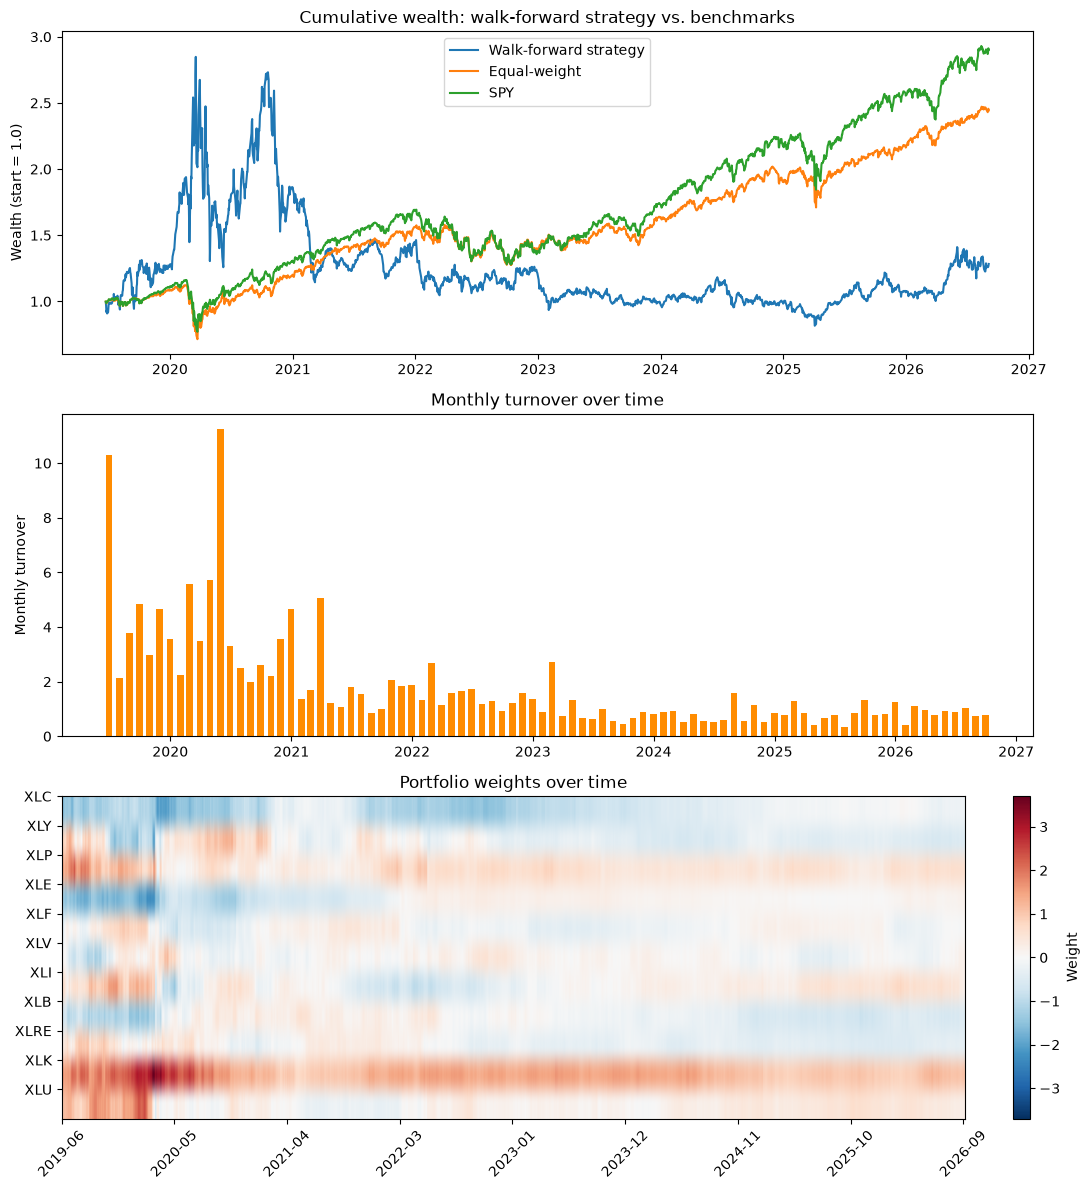

In [37]:
fig, axes = plt.subplots(3, 1, figsize=(11, 12))

wealth_strategy = np.cumprod(1 + perf_5["net_return"])
wealth_ew = np.cumprod(1 + ew_returns_oos)
wealth_spy = np.cumprod(1 + oos_spy_returns)
axes[0].plot(oos_dates, wealth_strategy, label="Walk-forward strategy")
axes[0].plot(oos_dates, wealth_ew, label="Equal-weight")
axes[0].plot(oos_dates, wealth_spy, label="SPY")
axes[0].set_ylabel("Wealth (start = 1.0)")
axes[0].set_title("Cumulative wealth: walk-forward strategy vs. benchmarks")
axes[0].legend()

monthly_turnover = perf_5["turnover"].resample("ME").sum()
axes[1].bar(monthly_turnover.index, monthly_turnover.values, width=20, color="darkorange")
axes[1].set_ylabel("Monthly turnover")
axes[1].set_title("Monthly turnover over time")

im = axes[2].imshow(weights_5.T.values, aspect="auto", cmap="RdBu_r",
                     vmin=-np.abs(weights_5.values).max(), vmax=np.abs(weights_5.values).max(),
                     extent=[0, len(weights_5), len(SECTOR_TICKERS), 0])
tick_step = max(1, len(weights_5) // 8)
tick_pos = np.arange(0, len(weights_5), tick_step)
axes[2].set_xticks(tick_pos)
axes[2].set_xticklabels([weights_5.index[i].strftime("%Y-%m") for i in tick_pos], rotation=45)
axes[2].set_yticks(range(len(SECTOR_TICKERS)))
axes[2].set_yticklabels(SECTOR_TICKERS)
axes[2].set_title("Portfolio weights over time")
fig.colorbar(im, ax=axes[2], label="Weight", fraction=0.02)

fig.tight_layout()
plt.show()

**Tearsheet** Over roughly seven years out-of-sample (2019-06 to 2026-09), the walk-forward mean-variance strategy is not fundable as built. It earns a 0.30 Sharpe ratio against 0.76 for equal-weight and 0.85 for SPY over the identical dates. More importantly, it suffers a 71% maximum drawdown, roughly double either benchmark's worst drawdown (36% and 34% respectively). This is driven by carrying an average gross leverage of 5.6x capital on estimates re-fit monthly from an expanding window that starts small (~253 days at the first estimate), and it costs real money to run: 22.1x annualized turnover consumed roughly 16% of capital in transaction costs and fees over the full period. I would not recommend allocating capital to this exact configuration. 

### 5.3 — Interpretation

In [38]:
beat_ew = m_strategy["sharpe"] > m_ew["sharpe"]
beat_spy = m_strategy["sharpe"] > m_spy["sharpe"]
print(f"Strategy Sharpe: {m_strategy['sharpe']:.3f} | EW Sharpe: {m_ew['sharpe']:.3f} | "
      f"SPY Sharpe: {m_spy['sharpe']:.3f}")
print(f"Strategy max DD: {m_strategy['max_drawdown']:.3f} | EW max DD: {m_ew['max_drawdown']:.3f} | "
      f"SPY max DD: {m_spy['max_drawdown']:.3f}")
print(f"Annualized turnover: {ann_turnover_5:.2f}x | Total cost drag: {total_cost_pct_5:.2f}% of capital")
print(f"Frictionless (Section 4.1) Sharpe was: {metrics_41.loc['Model (w*)', 'Sharpe']:.3f}")
print("Average gross leverage of w_t over the walk-forward run:",
      round(weights_5.abs().sum(axis=1).mean(), 2))

largest_abs_share = weights_5.abs().div(weights_5.abs().sum(axis=1), axis=0).max(axis=1)
top_sector = weights_5.abs().idxmax(axis=1)
print(f"Avg share of gross exposure in the single largest position: {largest_abs_share.mean():.2%}")
print(f"Number of distinct sectors that were ever the largest position: {top_sector.nunique()} of {len(SECTOR_TICKERS)}")
print(f"Number of months the top position changed: {(top_sector != top_sector.shift(1)).sum()} of {len(top_sector)}")

Strategy Sharpe: 0.296 | EW Sharpe: 0.764 | SPY Sharpe: 0.853
Strategy max DD: -0.714 | EW max DD: -0.363 | SPY max DD: -0.337
Annualized turnover: 22.13x | Total cost drag: 15.90% of capital
Frictionless (Section 4.1) Sharpe was: 0.737
Average gross leverage of w_t over the walk-forward run: 5.6
Avg share of gross exposure in the single largest position: 26.40%
Number of distinct sectors that were ever the largest position: 7 of 11
Number of months the top position changed: 41 of 1811


**(1) Does the walk-forward strategy beat the benchmarks?** No. Its 0.296 Sharpe ratio is well below equal-weight's 0.764 and SPY's 0.853 over the identical out-of-sample window, and the underperformance is not a close-call: it comes from a 71% maximum drawdown (vs. 36% and 34% for the benchmarks), not from a low mean return alone. The strategy is taking on far more risk than either passive alternative and is not compensated for it.

**(2) How did transaction costs change the conclusion relative to the frictionless Section 4.1 result?** Substantially. Section 4.1's single fixed-weight, frictionless portfolio achieved a 0.737 Sharpe ratio. The walk-forward version, re-estimating monthly from an expanding window that starts with as little as ~253 days of history, carrying 22.1 times annualized turnover and losing roughly 16% of capital to costs and fees over the period, falls all the way to 0.Realistic frictions plus noisier early-window estimates, not the mean-variance formula itself, are responsible for most of that gap.

**(3) What did the weight time series reveal?** The strategy runs concentrated, not diversified: the single largest position averages about 26% of gross exposure and while leadership does eventually rotate across 7 of the 11 sectors, it only changes 41 times over 1811 trading days, about once every 44 trading days on average. So the estimated target is persistent enough to reflect a real tilt for a couple of months at a time, but which sector it concentrates in drifts across the multi-year run rather than settling into one stable tilt. This is exactly the fragile, estimation-noise-driven behavior Sections 2.1–2.4 and 3.1–3.3 predicted for an unconstrained portfolio built on a small, expanding sample. 

**(4) With real money, what would change?** Two changes follow directly from earlier sections. First, Section 2.1 showed $\hat{\boldsymbol{\mu}}$ is far noisier than $\hat{\boldsymbol{\Sigma}}$ at realistic sample sizes, and Section 3.2 showed shrinking $\hat{\boldsymbol{\mu}}$ toward zero tames extreme weights quickly. A partial shrinkage of the mean estimate would directly reduce the 5. Second, Section 3.5 showed a leverage cap or long-only constraint gives up only 23–58% of unconstrained mean-variance utility on the full-sample estimate which is a real cost, but still smaller than the 71% drawdown realized here. Re-run this exact walk-forward loop with both changes before presenting it to a PM again.

## Section 6 — Bonus: Push the Strategy Further

Add a **minimum-variance portfolio** as an additional benchmark inside the exact same walk-forward machinery from Section 5 with the same expanding window, same monthly rebalance schedule, same cost and fee assumptions, so the comparison to the Section 5 mean-variance strategy isolates the effect of dropping $\hat{\boldsymbol{\mu}}$ from the optimization entirely. It was picked over a momentum overlay or full risk-parity specifically *because* Sections 2.1 and 3.2 built a strong case that $\hat{\boldsymbol{\mu}}$ is the noisiest input in the whole pipeline and minimum-variance is the natural experiment for asking how much of Section 5's poor result was caused by leaning on that noisy mean estimate at all.

In [39]:
def minvar_weights(Sigma):
    """Fully-invested (sum to 1) minimum-variance weights, shorts allowed:
    w = Sigma^-1 1 / (1' Sigma^-1 1)."""
    ones = np.ones(Sigma.shape[0])
    raw = np.linalg.solve(Sigma, ones)
    return raw / raw.sum()


def minvar_weight_fn(mu, Sigma):
    return minvar_weights(Sigma)


perf_6, weights_6 = walk_forward_backtest(minvar_weight_fn)
m_minvar = compute_metrics(perf_6["net_return"].to_numpy())
ann_turnover_6 = perf_6["turnover"].sum() * 252 / len(perf_6)
total_cost_pct_6 = perf_6["cost"].sum() * 100

bonus_comparison = pd.DataFrame({
    "Mean-variance (Sec. 5)": {**m_strategy, "ann_turnover": ann_turnover_5, "total_cost_pct": total_cost_pct_5},
    "Minimum-variance (bonus)": {**m_minvar, "ann_turnover": ann_turnover_6, "total_cost_pct": total_cost_pct_6},
    "Equal-weight": {**m_ew, "ann_turnover": np.nan, "total_cost_pct": np.nan},
    "SPY": {**m_spy, "ann_turnover": np.nan, "total_cost_pct": np.nan},
}).T
bonus_comparison.round(4)

,cum_return,ann_return,ann_vol,sharpe,max_drawdown,ann_turnover,total_cost_pct
Mean-variance (Sec. 5),0.2829,0.0353,0.4321,0.2958,-0.7135,22.1295,15.9034
Minimum-variance (bonus),0.1890,0.0244,0.1661,0.2284,-0.3402,2.1912,1.5747
Equal-weight,1.4432,0.1324,0.1855,0.7636,-0.3634,NaN,NaN
SPY,1.9015,0.1598,0.1965,0.8530,-0.3372,NaN,NaN


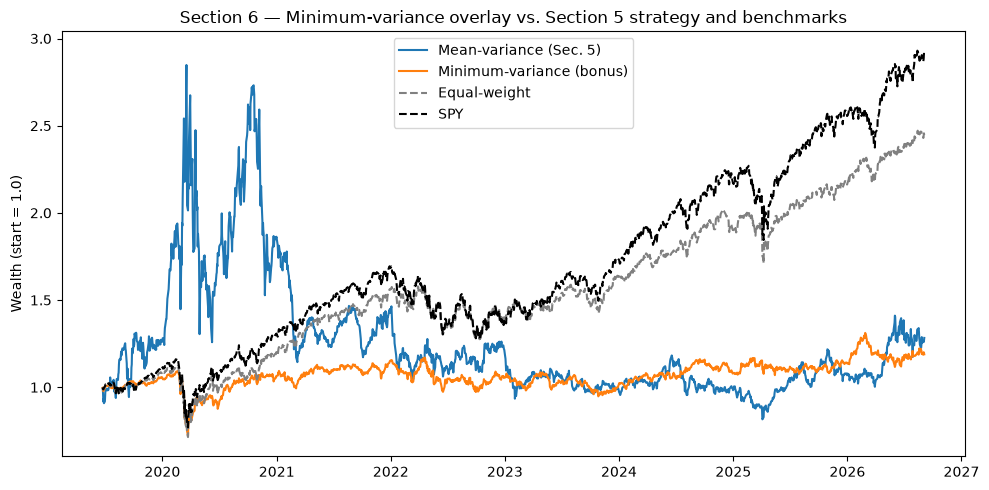

Avg gross leverage -- mean-variance: 5.60, min-variance: 2.50


In [40]:
fig, ax = plt.subplots(figsize=(10, 5))
wealth_minvar = np.cumprod(1 + perf_6["net_return"])
ax.plot(oos_dates, wealth_strategy, label="Mean-variance (Sec. 5)")
ax.plot(perf_6.index, wealth_minvar, label="Minimum-variance (bonus)")
ax.plot(oos_dates, wealth_ew, label="Equal-weight", linestyle="--", color="gray")
ax.plot(oos_dates, wealth_spy, label="SPY", linestyle="--", color="black")
ax.set_ylabel("Wealth (start = 1.0)")
ax.set_title("Section 6 — Minimum-variance overlay vs. Section 5 strategy and benchmarks")
ax.legend()
fig.tight_layout()
plt.show()

print(f"Avg gross leverage -- mean-variance: {weights_5.abs().sum(axis=1).mean():.2f}, "
      f"min-variance: {weights_6.abs().sum(axis=1).mean():.2f}")

**What this revealed.** Dropping $\hat{\boldsymbol{\mu}}$ entirely and optimizing purely for risk trades a bit of Sharpe ratio for a much safer risk profile. Minimum-variance's Sharpe (0.228) actually comes in a bit *below* Section 5's mean-variance Sharpe (0.296), so on Sharpe alone the mean-variance version looks better. But Sharpe hides risk from minimum-variance's. A maximum drawdown is 34%, in line with the equal-weight and SPY benchmarks, versus 71% for the mean-variance strategy. It gets there with less machinery against it. Average gross leverage of 2.5x versus 5.6x, annualized turnover of 2.2x versus 22, and total cost drag of 1.6% versus 15.9% of capital over the same walk-forward period. This is out-of-sample evidence for a nuanced version of this notebook's central finding from Sections 2–3: leaning on a noisy $\hat{\boldsymbol{\mu}}$ isn't *free* upside, but it comes with a leverage, turnover, and drawdown profile that would likely judge not worth the trade. 